In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("data/Nassau Candy Distributor.csv")

print(df.head())
print(df.shape)
print(df.columns)

   Row ID                      Order ID  Order Date   Ship Date  \
0       1  US-2021-103800-CHO-MIL-31000  03-01-2024  30-06-2026   
1       2  US-2021-112326-CHO-TRI-54000  04-01-2024  01-07-2026   
2       3  US-2021-112326-CHO-NUT-13000  04-01-2024  01-07-2026   
3       4  US-2021-112326-CHO-SCR-58000  04-01-2024  01-07-2026   
4       5  US-2021-141817-CHO-TRI-54000  05-01-2024  05-07-2026   

        Ship Mode  Customer ID Country/Region          City State/Province  \
0  Standard Class       103800  United States       Houston          Texas   
1  Standard Class       112326  United States    Naperville       Illinois   
2  Standard Class       112326  United States    Naperville       Illinois   
3  Standard Class       112326  United States    Naperville       Illinois   
4  Standard Class       141817  United States  Philadelphia   Pennsylvania   

  Postal Code   Division    Region     Product ID  \
0       77095  Chocolate  Interior  CHO-MIL-31000   
1       60540  Chocola

In [2]:
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Country/Region,City,State/Province,Postal Code,Division,Region,Product ID,Product Name,Sales,Units,Gross Profit,Cost
0,1,US-2021-103800-CHO-MIL-31000,03-01-2024,30-06-2026,Standard Class,103800,United States,Houston,Texas,77095,Chocolate,Interior,CHO-MIL-31000,Wonka Bar - Milk Chocolate,6.50,2,4.22,2.28
1,2,US-2021-112326-CHO-TRI-54000,04-01-2024,01-07-2026,Standard Class,112326,United States,Naperville,Illinois,60540,Chocolate,Interior,CHO-TRI-54000,Wonka Bar - Triple Dazzle Caramel,7.50,2,4.90,2.60
2,3,US-2021-112326-CHO-NUT-13000,04-01-2024,01-07-2026,Standard Class,112326,United States,Naperville,Illinois,60540,Chocolate,Interior,CHO-NUT-13000,Wonka Bar - Nutty Crunch Surprise,10.47,3,7.47,3.00
3,4,US-2021-112326-CHO-SCR-58000,04-01-2024,01-07-2026,Standard Class,112326,United States,Naperville,Illinois,60540,Chocolate,Interior,CHO-SCR-58000,Wonka Bar -Scrumdiddlyumptious,10.80,3,7.50,3.30
4,5,US-2021-141817-CHO-TRI-54000,05-01-2024,05-07-2026,Standard Class,141817,United States,Philadelphia,Pennsylvania,19143,Chocolate,Atlantic,CHO-TRI-54000,Wonka Bar - Triple Dazzle Caramel,11.25,3,7.35,3.90


In [3]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 10194
Number of columns: 18


In [4]:
print(df.isnull().sum())

Row ID            0
Order ID          0
Order Date        0
Ship Date         0
Ship Mode         0
Customer ID       0
Country/Region    0
City              0
State/Province    0
Postal Code       0
Division          0
Region            0
Product ID        0
Product Name      0
Sales             0
Units             0
Gross Profit      0
Cost              0
dtype: int64


In [5]:
print("Duplicate rows:", df.duplicated().sum())


Duplicate rows: 0


In [6]:
print(df[["Order Date", "Ship Date"]].head(10))
print(df[["Order Date", "Ship Date"]].dtypes)

   Order Date   Ship Date
0  03-01-2024  30-06-2026
1  04-01-2024  01-07-2026
2  04-01-2024  01-07-2026
3  04-01-2024  01-07-2026
4  05-01-2024  05-07-2026
5  06-01-2024  03-07-2026
6  06-01-2024  03-07-2026
7  06-01-2024  30-06-2026
8  06-01-2024  03-07-2026
9  06-01-2024  03-07-2026
Order Date    object
Ship Date     object
dtype: object


In [7]:
df["Order Date"] = pd.to_datetime(
    df["Order Date"], format="%d-%m-%Y"
)

df["Ship Date"] = pd.to_datetime(
    df["Ship Date"], format="%d-%m-%Y"
)

print(df[["Order Date", "Ship Date"]].dtypes)

Order Date    datetime64[ns]
Ship Date     datetime64[ns]
dtype: object


In [8]:
df["Shipping Lead Time"] = (
    df["Ship Date"] - df["Order Date"]
).dt.days

print(df["Shipping Lead Time"].describe())

count    10194.000000
mean      1320.841868
std        262.444892
min        904.000000
25%       1271.000000
50%       1274.000000
75%       1638.000000
max       1642.000000
Name: Shipping Lead Time, dtype: float64


In [9]:
print("Order Date Range:")
print(df["Order Date"].min())
print(df["Order Date"].max())

print("\nShip Date Range:")
print(df["Ship Date"].min())
print(df["Ship Date"].max())

Order Date Range:
2024-01-02 00:00:00
2025-12-31 00:00:00

Ship Date Range:
2026-06-30 00:00:00
2030-06-28 00:00:00


In [10]:
print(df[["Order Date", "Ship Date", "Shipping Lead Time"]].sample(10))

     Order Date  Ship Date  Shipping Lead Time
4769 2025-05-09 2028-11-03                1274
5896 2025-10-03 2029-03-29                1273
364  2024-04-13 2026-10-08                 908
7240 2025-03-21 2029-09-13                1637
2514 2024-05-08 2027-11-02                1273
1648 2024-11-20 2027-05-18                 909
5201 2025-07-14 2029-01-07                1273
7268 2025-03-25 2029-09-21                1641
5292 2025-07-23 2029-01-15                1272
5954 2025-10-13 2029-04-10                1275


In [11]:
print("Ship date before order date:",
      (df["Ship Date"] < df["Order Date"]).sum())

print("Lead time greater than 30 days:",
      (df["Shipping Lead Time"] > 30).sum())

print("Lead time less than 0 days:",
      (df["Shipping Lead Time"] < 0).sum())

Ship date before order date: 0
Lead time greater than 30 days: 10194
Lead time less than 0 days: 0


In [12]:
product_factory = {
    "Wonka Bar - Milk Chocolate": "Wicked Choccy's",
    "Wonka Bar - Nutty Crunch Surprise": "Lot's O' Nuts",
    "Laffy Taffy": "Sugar Shack"
}
print(product_factory["Wonka Bar - Milk Chocolate"])

Wicked Choccy's


In [13]:
product_factory = {
    "Wonka Bar - Nutty Crunch Surprise": "Lot's O' Nuts",
    "Wonka Bar - Fudge Mallows": "Lot's O' Nuts",
    "Wonka Bar -Scrumdiddlyumptious": "Lot's O' Nuts",

    "Wonka Bar - Milk Chocolate": "Wicked Choccy's",
    "Wonka Bar - Triple Dazzle Caramel": "Wicked Choccy's",

    "Laffy Taffy": "Sugar Shack",
    "SweeTARTS": "Sugar Shack",
    "Nerds": "Sugar Shack",
    "Fun Dip": "Sugar Shack",
    "Fizzy Lifting Drinks": "Sugar Shack",

    "Everlasting Gobstopper": "Secret Factory",
    "Lickable Wallpaper": "Secret Factory",
    "Wonka Gum": "Secret Factory",

    "Hair Toffee": "The Other Factory",
    "Kazookles": "The Other Factory"
}

In [14]:
df["Factory"] = df["Product Name"].map(product_factory)

print(df[["Product Name", "Factory"]].head(10))

                        Product Name          Factory
0         Wonka Bar - Milk Chocolate  Wicked Choccy's
1  Wonka Bar - Triple Dazzle Caramel  Wicked Choccy's
2  Wonka Bar - Nutty Crunch Surprise    Lot's O' Nuts
3     Wonka Bar -Scrumdiddlyumptious    Lot's O' Nuts
4  Wonka Bar - Triple Dazzle Caramel  Wicked Choccy's
5     Wonka Bar -Scrumdiddlyumptious    Lot's O' Nuts
6  Wonka Bar - Triple Dazzle Caramel  Wicked Choccy's
7         Wonka Bar - Milk Chocolate  Wicked Choccy's
8  Wonka Bar - Nutty Crunch Surprise    Lot's O' Nuts
9         Wonka Bar - Milk Chocolate  Wicked Choccy's


In [15]:
print("Unmapped products:", df["Factory"].isna().sum())

Unmapped products: 0


In [16]:
factory_coordinates = {
    "Lot's O' Nuts": (32.881893, -111.768036),
    "Wicked Choccy's": (32.076176, -81.088371),
    "Sugar Shack": (48.119140, -96.181150),
    "Secret Factory": (41.446333, -90.565487),
    "The Other Factory": (35.117500, -89.971107)
}

In [17]:
df["Factory Latitude"] = df["Factory"].map(
    lambda factory: factory_coordinates[factory][0]
)

df["Factory Longitude"] = df["Factory"].map(
    lambda factory: factory_coordinates[factory][1]
)

print(df[["Factory", "Factory Latitude", "Factory Longitude"]].head())

           Factory  Factory Latitude  Factory Longitude
0  Wicked Choccy's         32.076176         -81.088371
1  Wicked Choccy's         32.076176         -81.088371
2    Lot's O' Nuts         32.881893        -111.768036
3    Lot's O' Nuts         32.881893        -111.768036
4  Wicked Choccy's         32.076176         -81.088371


In [18]:
print("Missing factory latitudes:", df["Factory Latitude"].isna().sum())
print("Missing factory longitudes:", df["Factory Longitude"].isna().sum())

print(df[["Factory", "Factory Latitude", "Factory Longitude"]].drop_duplicates())

Missing factory latitudes: 0
Missing factory longitudes: 0
               Factory  Factory Latitude  Factory Longitude
0      Wicked Choccy's         32.076176         -81.088371
2        Lot's O' Nuts         32.881893        -111.768036
19      Secret Factory         41.446333         -90.565487
26   The Other Factory         35.117500         -89.971107
191        Sugar Shack         48.119140         -96.181150


In [19]:
import os

os.makedirs("outputs", exist_ok=True)

df.to_csv("outputs/cleaned_shipments.csv", index=False)

print("Dataset saved successfully!")
print("Final dataset shape:", df.shape)

Dataset saved successfully!
Final dataset shape: (10194, 22)


# EDA and business insights

In [20]:

import matplotlib.pyplot as plt

In [21]:
print(df.head())

   Row ID                      Order ID Order Date  Ship Date       Ship Mode  \
0       1  US-2021-103800-CHO-MIL-31000 2024-01-03 2026-06-30  Standard Class   
1       2  US-2021-112326-CHO-TRI-54000 2024-01-04 2026-07-01  Standard Class   
2       3  US-2021-112326-CHO-NUT-13000 2024-01-04 2026-07-01  Standard Class   
3       4  US-2021-112326-CHO-SCR-58000 2024-01-04 2026-07-01  Standard Class   
4       5  US-2021-141817-CHO-TRI-54000 2024-01-05 2026-07-05  Standard Class   

   Customer ID Country/Region          City State/Province Postal Code  ...  \
0       103800  United States       Houston          Texas       77095  ...   
1       112326  United States    Naperville       Illinois       60540  ...   
2       112326  United States    Naperville       Illinois       60540  ...   
3       112326  United States    Naperville       Illinois       60540  ...   
4       141817  United States  Philadelphia   Pennsylvania       19143  ...   

      Product ID                      

In [22]:
region_sales = df.groupby("Region")["Sales"].sum()

print(region_sales.sort_values(ascending=False))

Region
Pacific     46301.53
Atlantic    41197.24
Interior    32037.60
Gulf        22247.26
Name: Sales, dtype: float64


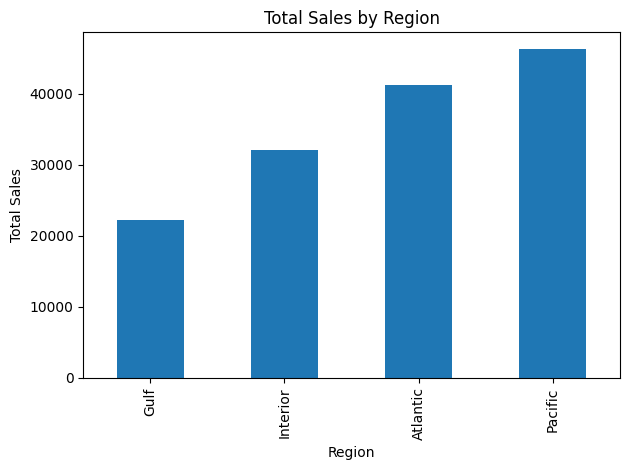

In [23]:
region_sales.sort_values().plot(kind="bar")

plt.title("Total Sales by Region")
plt.xlabel("Region")
plt.ylabel("Total Sales")
plt.tight_layout()
plt.show()

In [24]:
product_sales = (
    df.groupby("Product Name")["Sales"]
    .sum()
    .sort_values(ascending=False)
)

print(product_sales.head(10))

Product Name
Wonka Bar - Triple Dazzle Caramel    28485.00
Wonka Bar -Scrumdiddlyumptious       27874.80
Wonka Bar - Milk Chocolate           26867.75
Wonka Bar - Fudge Mallows            24890.40
Wonka Bar - Nutty Crunch Surprise    23574.95
Lickable Wallpaper                    7860.00
Kazookles                             1205.75
Wonka Gum                              597.50
Everlasting Gobstopper                 130.00
Fizzy Lifting Drinks                    78.75
Name: Sales, dtype: float64


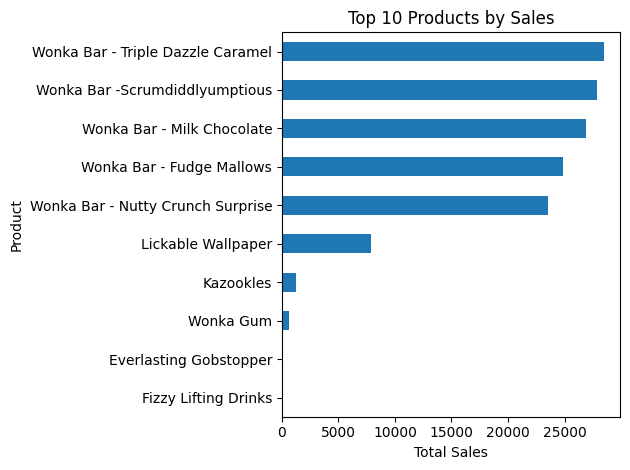

In [25]:
product_sales.head(10).sort_values().plot(kind="barh")

plt.title("Top 10 Products by Sales")
plt.xlabel("Total Sales")
plt.ylabel("Product")
plt.tight_layout()
plt.show()

In [26]:
mode_orders = df.groupby("Ship Mode")["Order ID"].nunique()

print(mode_orders)

Ship Mode
First Class       1312
Same Day           442
Second Class      1653
Standard Class    5142
Name: Order ID, dtype: int64


In [27]:
mode_sales = df.groupby("Ship Mode")["Sales"].sum()

print(mode_sales.sort_values(ascending=False))

Ship Mode
Standard Class    85490.35
Second Class      27860.22
First Class       21319.39
Same Day           7113.67
Name: Sales, dtype: float64


In [28]:
print(df["Shipping Lead Time"].describe())
print(df["Shipping Lead Time"].value_counts().head(10))

count    10194.000000
mean      1320.841868
std        262.444892
min        904.000000
25%       1271.000000
50%       1274.000000
75%       1638.000000
max       1642.000000
Name: Shipping Lead Time, dtype: float64
Shipping Lead Time
1273    1326
1274    1035
1639     896
1640     657
1275     612
1271     610
908      591
909      519
1272     456
1637     449
Name: count, dtype: int64


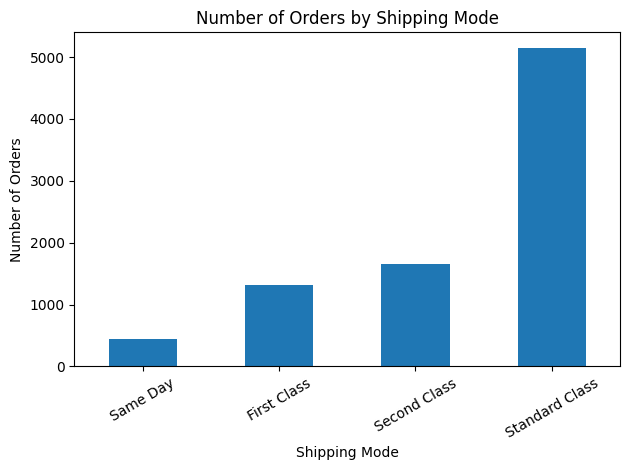

In [29]:
mode_orders.sort_values().plot(kind="bar")

plt.title("Number of Orders by Shipping Mode")
plt.xlabel("Shipping Mode")
plt.ylabel("Number of Orders")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [30]:
region_summary = df.groupby("Region").agg(
    Total_Sales=("Sales", "sum"),
    Total_Orders=("Order ID", "nunique")
)

print(region_summary.sort_values(
    "Total_Sales", ascending=False
))

          Total_Sales  Total_Orders
Region                             
Pacific      46301.53          2744
Atlantic     41197.24          2476
Interior     32037.60          1979
Gulf         22247.26          1350


In [31]:
region_summary.to_csv("outputs/region_summary.csv")
print("Regional summary saved!")

Regional summary saved!


# Route Analytics

In [32]:
import pandas as pd

df = pd.read_csv("outputs/cleaned_shipments.csv")

print(df.head())
print(df.shape)

   Row ID                      Order ID  Order Date   Ship Date  \
0       1  US-2021-103800-CHO-MIL-31000  2024-01-03  2026-06-30   
1       2  US-2021-112326-CHO-TRI-54000  2024-01-04  2026-07-01   
2       3  US-2021-112326-CHO-NUT-13000  2024-01-04  2026-07-01   
3       4  US-2021-112326-CHO-SCR-58000  2024-01-04  2026-07-01   
4       5  US-2021-141817-CHO-TRI-54000  2024-01-05  2026-07-05   

        Ship Mode  Customer ID Country/Region          City State/Province  \
0  Standard Class       103800  United States       Houston          Texas   
1  Standard Class       112326  United States    Naperville       Illinois   
2  Standard Class       112326  United States    Naperville       Illinois   
3  Standard Class       112326  United States    Naperville       Illinois   
4  Standard Class       141817  United States  Philadelphia   Pennsylvania   

  Postal Code  ...     Product ID                       Product Name  Sales  \
0       77095  ...  CHO-MIL-31000         Wonka B

In [33]:
print(df[["Factory", "State/Province", "Order ID",
          "Shipping Lead Time"]].head())

           Factory State/Province                      Order ID  \
0  Wicked Choccy's          Texas  US-2021-103800-CHO-MIL-31000   
1  Wicked Choccy's       Illinois  US-2021-112326-CHO-TRI-54000   
2    Lot's O' Nuts       Illinois  US-2021-112326-CHO-NUT-13000   
3    Lot's O' Nuts       Illinois  US-2021-112326-CHO-SCR-58000   
4  Wicked Choccy's   Pennsylvania  US-2021-141817-CHO-TRI-54000   

   Shipping Lead Time  
0                 909  
1                 909  
2                 909  
3                 909  
4                 912  


In [34]:
route_volume = (
    df.groupby(["Factory", "State/Province"])["Order ID"]
    .nunique()
    .reset_index(name="Total Shipments")
)

print(route_volume.head(10))

         Factory        State/Province  Total Shipments
0  Lot's O' Nuts               Alabama               30
1  Lot's O' Nuts               Alberta               12
2  Lot's O' Nuts               Arizona               94
3  Lot's O' Nuts              Arkansas               25
4  Lot's O' Nuts      British Columbia               18
5  Lot's O' Nuts            California              944
6  Lot's O' Nuts              Colorado               82
7  Lot's O' Nuts           Connecticut               40
8  Lot's O' Nuts              Delaware               39
9  Lot's O' Nuts  District of Columbia                6


In [35]:
route_summary = df.groupby(
    ["Factory", "State/Province"]
).agg(
    Total_Shipments=("Order ID", "nunique"),
    Average_Lead_Time=("Shipping Lead Time", "mean")
).reset_index()

print(route_summary.head(10))

         Factory        State/Province  Total_Shipments  Average_Lead_Time
0  Lot's O' Nuts               Alabama               30        1295.205882
1  Lot's O' Nuts               Alberta               12        1273.875000
2  Lot's O' Nuts               Arizona               94        1306.198198
3  Lot's O' Nuts              Arkansas               25        1285.354839
4  Lot's O' Nuts      British Columbia               18        1273.777778
5  Lot's O' Nuts            California              944        1316.910222
6  Lot's O' Nuts              Colorado               82        1347.533981
7  Lot's O' Nuts           Connecticut               40        1420.553191
8  Lot's O' Nuts              Delaware               39        1273.302326
9  Lot's O' Nuts  District of Columbia                6        1365.875000


In [36]:
# Mark shipments with lead time above 30 days
df["Is Delayed"] = df["Shipping Lead Time"] > 30

# Calculate delay percentage for each factory-state route
route_delay = df.groupby(
    ["Factory", "State/Province"]
).agg(
    Delay_Count=("Is Delayed", "sum"),
    Total_Records=("Is Delayed", "count")
).reset_index()

route_delay["Delay_Percentage"] = (
    route_delay["Delay_Count"] /
    route_delay["Total_Records"] * 100
)

print(route_delay.head(10))

         Factory        State/Province  Delay_Count  Total_Records  \
0  Lot's O' Nuts               Alabama           34             34   
1  Lot's O' Nuts               Alberta           16             16   
2  Lot's O' Nuts               Arizona          111            111   
3  Lot's O' Nuts              Arkansas           31             31   
4  Lot's O' Nuts      British Columbia           18             18   
5  Lot's O' Nuts            California         1125           1125   
6  Lot's O' Nuts              Colorado          103            103   
7  Lot's O' Nuts           Connecticut           47             47   
8  Lot's O' Nuts              Delaware           43             43   
9  Lot's O' Nuts  District of Columbia            8              8   

   Delay_Percentage  
0             100.0  
1             100.0  
2             100.0  
3             100.0  
4             100.0  
5             100.0  
6             100.0  
7             100.0  
8             100.0  
9        

In [37]:
# Combine route volume and lead-time metrics
route_summary = route_summary.merge(
    route_delay[
        ["Factory", "State/Province", "Delay_Percentage"]
    ],
    on=["Factory", "State/Province"],
    how="left"
)

print(route_summary.head(10))

         Factory        State/Province  Total_Shipments  Average_Lead_Time  \
0  Lot's O' Nuts               Alabama               30        1295.205882   
1  Lot's O' Nuts               Alberta               12        1273.875000   
2  Lot's O' Nuts               Arizona               94        1306.198198   
3  Lot's O' Nuts              Arkansas               25        1285.354839   
4  Lot's O' Nuts      British Columbia               18        1273.777778   
5  Lot's O' Nuts            California              944        1316.910222   
6  Lot's O' Nuts              Colorado               82        1347.533981   
7  Lot's O' Nuts           Connecticut               40        1420.553191   
8  Lot's O' Nuts              Delaware               39        1273.302326   
9  Lot's O' Nuts  District of Columbia                6        1365.875000   

   Delay_Percentage  
0             100.0  
1             100.0  
2             100.0  
3             100.0  
4             100.0  
5        

In [38]:
route_summary.to_csv(
    "outputs/route_summary.csv",
    index=False
)

print("Route summary saved successfully!")

Route summary saved successfully!


In [39]:
top_routes = route_summary.sort_values(
    by="Total_Shipments",
    ascending=False
)

print(top_routes.head(10))

             Factory State/Province  Total_Shipments  Average_Lead_Time  \
5      Lot's O' Nuts     California              944        1316.910222   
144  Wicked Choccy's     California              689        1320.326853   
34     Lot's O' Nuts       New York              544        1330.516279   
49     Lot's O' Nuts          Texas              479        1310.460457   
173  Wicked Choccy's       New York              353        1311.883028   
189  Wicked Choccy's          Texas              326        1315.608247   
42     Lot's O' Nuts   Pennsylvania              270        1315.063444   
13     Lot's O' Nuts       Illinois              235        1319.932584   
53     Lot's O' Nuts     Washington              230        1343.962825   
38     Lot's O' Nuts           Ohio              218        1334.114504   

     Delay_Percentage  
5               100.0  
144             100.0  
34              100.0  
49              100.0  
173             100.0  
189             100.0  
42    

In [40]:
print(top_routes.tail(10))

               Factory  State/Province  Total_Shipments  Average_Lead_Time  \
110        Sugar Shack      Washington                1             1638.0   
108        Sugar Shack       Tennessee                1             1272.0   
107        Sugar Shack    Rhode Island                1             1273.0   
103        Sugar Shack      New Jersey                1             1642.0   
91      Secret Factory            Utah                1             1275.0   
92      Secret Factory         Vermont                1             1273.0   
96         Sugar Shack         Arizona                1             1274.0   
134  The Other Factory  South Carolina                1             1273.0   
133  The Other Factory    Rhode Island                1             1273.0   
175    Wicked Choccy's    North Dakota                1             1637.0   

     Delay_Percentage  
110             100.0  
108             100.0  
107             100.0  
103             100.0  
91              100.0

In [41]:
top_routes.to_csv(
    "outputs/routes_ranked_by_volume.csv",
    index=False
)

print("Ranked routes saved successfully!")

Ranked routes saved successfully!


In [42]:
# Count total factory-to-state routes
print("Total routes:", len(route_summary))

# Show the 10 routes handling the most orders
print(
    route_summary.sort_values(
        by="Total_Shipments",
        ascending=False
    ).head(10)
)

Total routes: 196
             Factory State/Province  Total_Shipments  Average_Lead_Time  \
5      Lot's O' Nuts     California              944        1316.910222   
144  Wicked Choccy's     California              689        1320.326853   
34     Lot's O' Nuts       New York              544        1330.516279   
49     Lot's O' Nuts          Texas              479        1310.460457   
173  Wicked Choccy's       New York              353        1311.883028   
189  Wicked Choccy's          Texas              326        1315.608247   
42     Lot's O' Nuts   Pennsylvania              270        1315.063444   
13     Lot's O' Nuts       Illinois              235        1319.932584   
53     Lot's O' Nuts     Washington              230        1343.962825   
38     Lot's O' Nuts           Ohio              218        1334.114504   

     Delay_Percentage  
5               100.0  
144             100.0  
34              100.0  
49              100.0  
173             100.0  
189         

In [43]:
print("Number of factories:", df["Factory"].nunique())
print("Number of destination states/provinces:",
      df["State/Province"].nunique())

Number of factories: 5
Number of destination states/provinces: 59


# Geographic Shipping Analysis

In [44]:
state_summary = df.groupby("State/Province").agg(
    Total_Shipments=("Order ID", "nunique"),
    Total_Sales=("Sales", "sum"),
    Number_of_Factories=("Factory", "nunique")
).reset_index()

print(
    state_summary.sort_values(
        by="Total_Shipments",
        ascending=False
    ).head(10)
)

    State/Province  Total_Shipments  Total_Sales  Number_of_Factories
5       California             1686     27917.40                    5
34        New York              942     15541.03                    5
51           Texas              833     13416.09                    5
43    Pennsylvania              487      8027.03                    5
13        Illinois              433      6898.96                    4
55      Washington              432      6921.15                    5
39            Ohio              392      6768.95                    5
10         Florida              319      4804.02                    5
36  North Carolina              216      3450.86                    4
23        Michigan              209      3331.00                    4


In [45]:
state_summary.to_csv(
    "outputs/state_summary.csv",
    index=False
)

print("State summary saved successfully!")

State summary saved successfully!


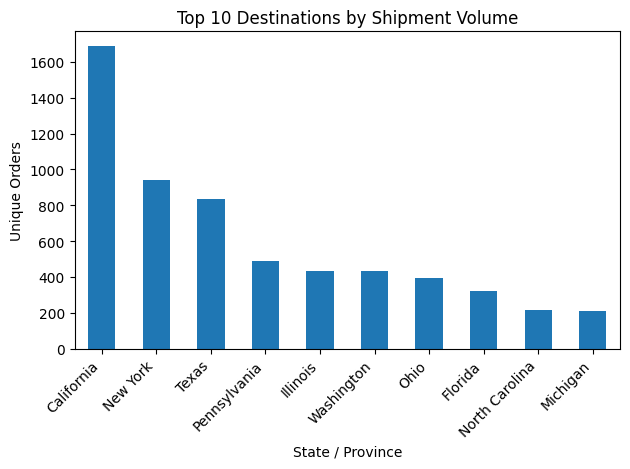

In [46]:
import matplotlib.pyplot as plt

top_states = state_summary.sort_values(
    by="Total_Shipments",
    ascending=False
).head(10)

top_states.plot(
    x="State/Province",
    y="Total_Shipments",
    kind="bar",
    legend=False
)

plt.title("Top 10 Destinations by Shipment Volume")
plt.xlabel("State / Province")
plt.ylabel("Unique Orders")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

<Figure size 1000x600 with 0 Axes>

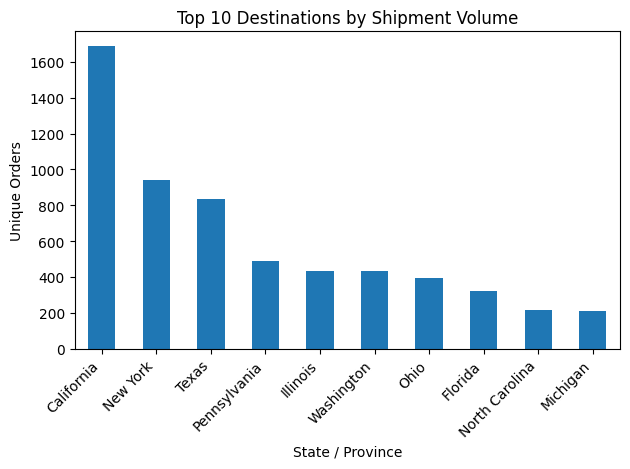

In [47]:
plt.figure(figsize=(10, 6))

top_states.plot(
    x="State/Province",
    y="Total_Shipments",
    kind="bar",
    legend=False
)

plt.title("Top 10 Destinations by Shipment Volume")
plt.xlabel("State / Province")
plt.ylabel("Unique Orders")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()

plt.savefig("outputs/top_10_destinations.png", dpi=300)
plt.show()

Top 10 states by average shipping lead time:
State/Province
West Virginia           1638.000000
North Dakota            1637.857143
Saskatchewan            1457.000000
Manitoba                1455.333333
Iowa                    1443.900000
New Mexico              1441.837838
Vermont                 1438.909091
Prince Edward Island    1420.300000
South Dakota            1395.916667
Tennessee               1391.486339
Name: Shipping Lead Time, dtype: float64


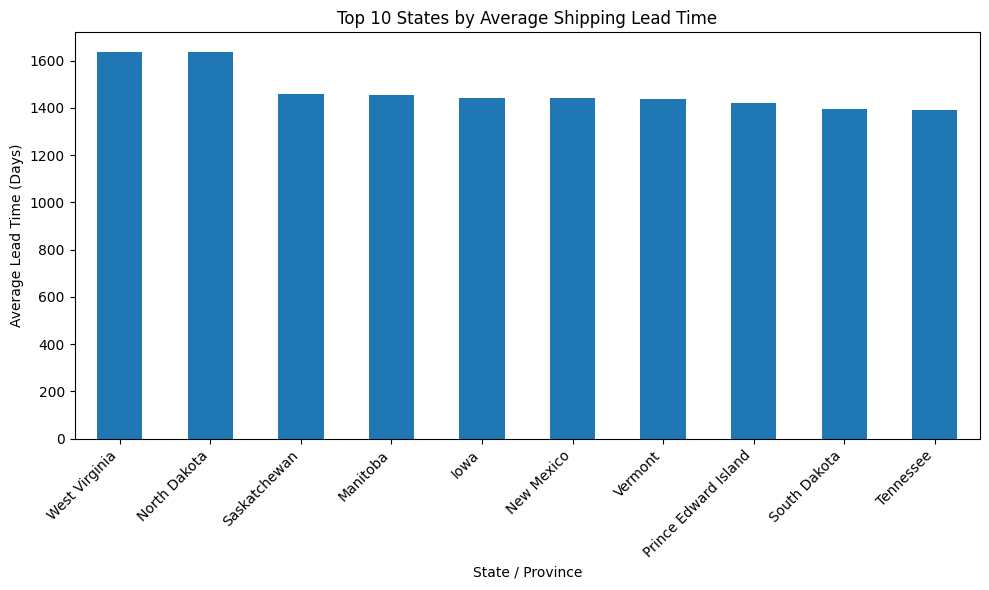

In [48]:
# Group shipments by destination state
state_delay = (
    df.groupby("State/Province")["Shipping Lead Time"]
    .mean()
    .sort_values(ascending=False)
)

# Select the 10 states with the highest average lead time
top_delay_states = state_delay.head(10)

# Display the results
print("Top 10 states by average shipping lead time:")
print(top_delay_states)

# Create a bar chart
top_delay_states.plot(kind="bar", figsize=(10, 6))

plt.title("Top 10 States by Average Shipping Lead Time")
plt.xlabel("State / Province")
plt.ylabel("Average Lead Time (Days)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()

# Save the chart
plt.savefig("outputs/top_10_shipping_delays.png", dpi=300)
plt.show()

In [50]:
# Check the original order and shipping dates
print("Order Date samples:")
print(df["Order Date"].head(10))

print("\nShip Date samples:")
print(df["Ship Date"].head(10))

# Make sure both columns are datetime values
df["Order Date"] = pd.to_datetime(df["Order Date"], errors="coerce")
df["Ship Date"] = pd.to_datetime(df["Ship Date"], errors="coerce")

# Calculate shipping lead time in days
df["Shipping Lead Time"] = (
    df["Ship Date"] - df["Order Date"]
).dt.days

# Check the smallest and largest lead times
print("\nMinimum lead time:", df["Shipping Lead Time"].min())
print("Maximum lead time:", df["Shipping Lead Time"].max())

# Display the most common lead times
print("\nMost common lead times:")
print(df["Shipping Lead Time"].value_counts().head(10))

Order Date samples:
0    2024-01-03
1    2024-01-04
2    2024-01-04
3    2024-01-04
4    2024-01-05
5    2024-01-06
6    2024-01-06
7    2024-01-06
8    2024-01-06
9    2024-01-06
Name: Order Date, dtype: object

Ship Date samples:
0    2026-06-30
1    2026-07-01
2    2026-07-01
3    2026-07-01
4    2026-07-05
5    2026-07-03
6    2026-07-03
7    2026-06-30
8    2026-07-03
9    2026-07-03
Name: Ship Date, dtype: object

Minimum lead time: 904
Maximum lead time: 1642

Most common lead times:
Shipping Lead Time
1273    1326
1274    1035
1639     896
1640     657
1275     612
1271     610
908      591
909      519
1272     456
1637     449
Name: count, dtype: int64


In [51]:
# Find shipments with unusually long delivery times
long_shipments = df[df["Shipping Lead Time"] > 30]

# Count the suspicious records
print("Shipments taking more than 30 days:",
      len(long_shipments))

# Display some examples
print(
    long_shipments[
        ["Order ID", "Order Date", "Ship Date", "Shipping Lead Time"]
    ].head(10)
)

Shipments taking more than 30 days: 10194
                       Order ID Order Date  Ship Date  Shipping Lead Time
0  US-2021-103800-CHO-MIL-31000 2024-01-03 2026-06-30                 909
1  US-2021-112326-CHO-TRI-54000 2024-01-04 2026-07-01                 909
2  US-2021-112326-CHO-NUT-13000 2024-01-04 2026-07-01                 909
3  US-2021-112326-CHO-SCR-58000 2024-01-04 2026-07-01                 909
4  US-2021-141817-CHO-TRI-54000 2024-01-05 2026-07-05                 912
5  US-2021-167199-CHO-SCR-58000 2024-01-06 2026-07-03                 909
6  US-2021-167199-CHO-TRI-54000 2024-01-06 2026-07-03                 909
7  US-2021-106054-CHO-MIL-31000 2024-01-06 2026-06-30                 906
8  US-2021-167199-CHO-NUT-13000 2024-01-06 2026-07-03                 909
9  US-2021-167199-CHO-MIL-31000 2024-01-06 2026-07-03                 909


In [52]:
# Calculate the difference between the two dates
date_difference = (
    df["Ship Date"] - df["Order Date"]
).dt.days

# Check the distribution of shipping durations
print("Minimum days:", date_difference.min())
print("Maximum days:", date_difference.max())
print("Median days:", date_difference.median())

# Check how many shipments fall within each duration range
print("\nShipping duration ranges:")

print("0–7 days:", ((date_difference >= 0) & (date_difference <= 7)).sum())

print("8–30 days:", ((date_difference > 7) & (date_difference <= 30)).sum())

print("More than 30 days:", (date_difference > 30).sum())

Minimum days: 904
Maximum days: 1642
Median days: 1274.0

Shipping duration ranges:
0–7 days: 0
8–30 days: 0
More than 30 days: 10194


In [53]:
# Compare the earliest and latest dates in the dataset
print("Order date range:")
print("Earliest:", df["Order Date"].min())
print("Latest:", df["Order Date"].max())

print("\nShip date range:")
print("Earliest:", df["Ship Date"].min())
print("Latest:", df["Ship Date"].max())

# Check the most common differences between shipping and order dates
print("\nMost common shipping durations:")
print(df["Shipping Lead Time"].value_counts().head(15))

# Check whether the dates follow a consistent pattern
print("\nSample order and shipping dates:")
print(
    df[["Order ID", "Order Date", "Ship Date",
        "Shipping Lead Time"]].sample(10, random_state=42)
)

Order date range:
Earliest: 2024-01-02 00:00:00
Latest: 2025-12-31 00:00:00

Ship date range:
Earliest: 2026-06-30 00:00:00
Latest: 2030-06-28 00:00:00

Most common shipping durations:
Shipping Lead Time
1273    1326
1274    1035
1639     896
1640     657
1275     612
1271     610
908      591
909      519
1272     456
1637     449
1638     411
1641     397
1276     293
906      289
1269     258
Name: count, dtype: int64

Sample order and shipping dates:
                           Order ID Order Date  Ship Date  Shipping Lead Time
6636   US-2023-108777-CHO-FUD-51000 2025-12-12 2029-06-03                1269
3742   US-2022-102778-CHO-TRI-54000 2024-11-21 2028-05-16                1272
5114   US-2023-153577-CHO-TRI-54000 2025-06-27 2028-12-21                1273
6505   US-2023-161025-CHO-FUD-51000 2025-12-03 2029-05-31                1275
10072  US-2024-155376-CHO-SCR-58000 2025-12-22 2030-06-19                1640
6520   US-2023-114489-CHO-FUD-51000 2025-12-05 2029-05-31                

In [54]:
# Load the original CSV separately
original_df = pd.read_csv("data/Nassau Candy Distributor.csv")

# Display the original date values
print("Original CSV date samples:")
print(original_df[["Order Date", "Ship Date"]].head(10))

# Check the original date ranges
print("\nOriginal Order Date range:")
print(original_df["Order Date"].min())
print(original_df["Order Date"].max())

print("\nOriginal Ship Date range:")
print(original_df["Ship Date"].min())
print(original_df["Ship Date"].max())

Original CSV date samples:
   Order Date   Ship Date
0  03-01-2024  30-06-2026
1  04-01-2024  01-07-2026
2  04-01-2024  01-07-2026
3  04-01-2024  01-07-2026
4  05-01-2024  05-07-2026
5  06-01-2024  03-07-2026
6  06-01-2024  03-07-2026
7  06-01-2024  30-06-2026
8  06-01-2024  03-07-2026
9  06-01-2024  03-07-2026

Original Order Date range:
01-01-2025
31-12-2025

Original Ship Date range:
01-01-2027
31-12-2029


In [55]:
# Convert original date columns using the known day-month-year format
original_df["Order Date"] = pd.to_datetime(
    original_df["Order Date"],
    format="%d-%m-%Y",
    errors="coerce"
)

original_df["Ship Date"] = pd.to_datetime(
    original_df["Ship Date"],
    format="%d-%m-%Y",
    errors="coerce"
)

# Calculate shipping duration from the original data
original_df["Lead Time"] = (
    original_df["Ship Date"] - original_df["Order Date"]
).dt.days

# Check the duration distribution
print("Lead time statistics:")
print(original_df["Lead Time"].describe())

# Check the first 10 records
print("\nFirst 10 records:")
print(
    original_df[
        ["Order Date", "Ship Date", "Lead Time"]
    ].head(10)
)

Lead time statistics:
count    10194.000000
mean      1320.841868
std        262.444892
min        904.000000
25%       1271.000000
50%       1274.000000
75%       1638.000000
max       1642.000000
Name: Lead Time, dtype: float64

First 10 records:
  Order Date  Ship Date  Lead Time
0 2024-01-03 2026-06-30        909
1 2024-01-04 2026-07-01        909
2 2024-01-04 2026-07-01        909
3 2024-01-04 2026-07-01        909
4 2024-01-05 2026-07-05        912
5 2024-01-06 2026-07-03        909
6 2024-01-06 2026-07-03        909
7 2024-01-06 2026-06-30        906
8 2024-01-06 2026-07-03        909
9 2024-01-06 2026-07-03        909


In [56]:
# Check whether shipping dates are concentrated
# around particular dates or years.

print("Shipping dates by year:")
print(original_df["Ship Date"].dt.year.value_counts().sort_index())

print("\nMost common shipping dates:")
print(original_df["Ship Date"].value_counts().head(10))

# Compare order and shipping dates
print("\nOrder dates by year:")
print(original_df["Order Date"].dt.year.value_counts().sort_index())

Shipping dates by year:
Ship Date
2026     711
2027    2089
2028    2367
2029    2899
2030    2128
Name: count, dtype: int64

Most common shipping dates:
Ship Date
2028-06-07    38
2030-05-29    35
2030-03-19    34
2030-05-14    32
2030-02-27    30
2030-03-08    30
2030-06-04    30
2027-03-06    28
2030-03-01    27
2030-05-11    27
Name: count, dtype: int64

Order dates by year:
Order Date
2024    4181
2025    6013
Name: count, dtype: int64


In [57]:
# Display the original dates exactly as stored in the CSV
original_raw = pd.read_csv("data/Nassau Candy Distributor.csv")

print("Original raw date values:")
print(original_raw[["Order Date", "Ship Date"]].head(10))

# Check the data types before conversion
print("\nOriginal column data types:")
print(original_raw[["Order Date", "Ship Date"]].dtypes)

# Check the first few unique shipping dates
print("\nUnique shipping dates:")
print(original_raw["Ship Date"].head(20).tolist())

Original raw date values:
   Order Date   Ship Date
0  03-01-2024  30-06-2026
1  04-01-2024  01-07-2026
2  04-01-2024  01-07-2026
3  04-01-2024  01-07-2026
4  05-01-2024  05-07-2026
5  06-01-2024  03-07-2026
6  06-01-2024  03-07-2026
7  06-01-2024  30-06-2026
8  06-01-2024  03-07-2026
9  06-01-2024  03-07-2026

Original column data types:
Order Date    object
Ship Date     object
dtype: object

Unique shipping dates:
['30-06-2026', '01-07-2026', '01-07-2026', '01-07-2026', '05-07-2026', '03-07-2026', '03-07-2026', '30-06-2026', '03-07-2026', '03-07-2026', '03-07-2026', '01-07-2026', '03-07-2026', '03-07-2026', '05-07-2026', '05-07-2026', '06-07-2026', '06-07-2026', '08-07-2026', '08-07-2026']


In [58]:
# Convert the original CSV dates using day-month-year format
original_raw["Order Date"] = pd.to_datetime(
    original_raw["Order Date"],
    format="%d-%m-%Y",
    errors="coerce"
)

original_raw["Ship Date"] = pd.to_datetime(
    original_raw["Ship Date"],
    format="%d-%m-%Y",
    errors="coerce"
)

# Calculate the actual duration from the original dates
original_raw["Actual Lead Time"] = (
    original_raw["Ship Date"] - original_raw["Order Date"]
).dt.days

# Display the results
print("Actual lead time statistics:")
print(original_raw["Actual Lead Time"].describe())

print("\nSample shipping records:")
print(
    original_raw[
        ["Order Date", "Ship Date", "Actual Lead Time"]
    ].head(10)
)

# Check whether shipping occurs before ordering
print(
    "\nShipping before order:",
    (original_raw["Actual Lead Time"] < 0).sum()
)

Actual lead time statistics:
count    10194.000000
mean      1320.841868
std        262.444892
min        904.000000
25%       1271.000000
50%       1274.000000
75%       1638.000000
max       1642.000000
Name: Actual Lead Time, dtype: float64

Sample shipping records:
  Order Date  Ship Date  Actual Lead Time
0 2024-01-03 2026-06-30               909
1 2024-01-04 2026-07-01               909
2 2024-01-04 2026-07-01               909
3 2024-01-04 2026-07-01               909
4 2024-01-05 2026-07-05               912
5 2024-01-06 2026-07-03               909
6 2024-01-06 2026-07-03               909
7 2024-01-06 2026-06-30               906
8 2024-01-06 2026-07-03               909
9 2024-01-06 2026-07-03               909

Shipping before order: 0


In [59]:
# Compare the original order and shipping dates
# to check whether a consistent date offset exists.

original_raw["Lead Time"] = (
    original_raw["Ship Date"] - original_raw["Order Date"]
).dt.days

print("Lead time frequency:")
print(original_raw["Lead Time"].value_counts().head(15))

print("\nLead time by order year:")
print(
    original_raw.groupby(
        original_raw["Order Date"].dt.year
    )["Lead Time"].agg(["count", "mean", "min", "max"])
)

print("\nOrder and ship date samples:")
print(
    original_raw[
        ["Order Date", "Ship Date", "Lead Time"]
    ].sample(10, random_state=42)
)

Lead time frequency:
Lead Time
1273    1326
1274    1035
1639     896
1640     657
1275     612
1271     610
908      591
909      519
1272     456
1637     449
1638     411
1641     397
1276     293
906      289
1269     258
Name: count, dtype: int64

Lead time by order year:
            count         mean   min   max
Order Date                                
2024         4181  1094.018417   904  1277
2025         6013  1478.558290  1269  1642

Order and ship date samples:
      Order Date  Ship Date  Lead Time
6636  2025-12-12 2029-06-03       1269
3742  2024-11-21 2028-05-16       1272
5114  2025-06-27 2028-12-21       1273
6505  2025-12-03 2029-05-31       1275
10072 2025-12-22 2030-06-19       1640
6520  2025-12-05 2029-05-31       1273
3149  2024-09-11 2028-03-07       1273
2876  2024-07-23 2028-01-17       1273
5610  2025-09-05 2029-02-26       1270
7742  2025-05-27 2029-11-23       1641


In [60]:
# Check the year and month for order and shipping dates
date_check = original_raw[
    ["Order Date", "Ship Date", "Lead Time"]
].copy()

date_check["Order Year"] = date_check["Order Date"].dt.year
date_check["Order Month"] = date_check["Order Date"].dt.month

date_check["Ship Year"] = date_check["Ship Date"].dt.year
date_check["Ship Month"] = date_check["Ship Date"].dt.month

# Display sample records for comparison
print("Order and shipping date comparison:")
print(date_check.head(15).to_string(index=False))

# Check the difference in calendar years
date_check["Year Difference"] = (
    date_check["Ship Year"] - date_check["Order Year"]
)

print("\nYear difference frequency:")
print(date_check["Year Difference"].value_counts().sort_index())

# Check whether the original records contain varying year gaps
print("\nYear difference by order year:")
print(
    date_check.groupby("Order Year")["Year Difference"]
    .value_counts()
    .sort_index()
)

Order and shipping date comparison:
Order Date  Ship Date  Lead Time  Order Year  Order Month  Ship Year  Ship Month
2024-01-03 2026-06-30        909        2024            1       2026           6
2024-01-04 2026-07-01        909        2024            1       2026           7
2024-01-04 2026-07-01        909        2024            1       2026           7
2024-01-04 2026-07-01        909        2024            1       2026           7
2024-01-05 2026-07-05        912        2024            1       2026           7
2024-01-06 2026-07-03        909        2024            1       2026           7
2024-01-06 2026-07-03        909        2024            1       2026           7
2024-01-06 2026-06-30        906        2024            1       2026           6
2024-01-06 2026-07-03        909        2024            1       2026           7
2024-01-06 2026-07-03        909        2024            1       2026           7
2024-01-06 2026-07-03        909        2024            1       2026     

In [61]:
# Display all columns that may contain date information
date_columns = [
    col for col in original_raw.columns
    if "date" in col.lower()
]

print("Date-related columns:")
print(date_columns)

# Display sample values from every date-related column
for col in date_columns:
    print(f"\n{col}:")
    print(original_raw[col].head(10).to_list())

# Show all available column names
print("\nAll dataset columns:")
print(original_raw.columns.to_list())

Date-related columns:
['Order Date', 'Ship Date']

Order Date:
[Timestamp('2024-01-03 00:00:00'), Timestamp('2024-01-04 00:00:00'), Timestamp('2024-01-04 00:00:00'), Timestamp('2024-01-04 00:00:00'), Timestamp('2024-01-05 00:00:00'), Timestamp('2024-01-06 00:00:00'), Timestamp('2024-01-06 00:00:00'), Timestamp('2024-01-06 00:00:00'), Timestamp('2024-01-06 00:00:00'), Timestamp('2024-01-06 00:00:00')]

Ship Date:
[Timestamp('2026-06-30 00:00:00'), Timestamp('2026-07-01 00:00:00'), Timestamp('2026-07-01 00:00:00'), Timestamp('2026-07-01 00:00:00'), Timestamp('2026-07-05 00:00:00'), Timestamp('2026-07-03 00:00:00'), Timestamp('2026-07-03 00:00:00'), Timestamp('2026-06-30 00:00:00'), Timestamp('2026-07-03 00:00:00'), Timestamp('2026-07-03 00:00:00')]

All dataset columns:
['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Country/Region', 'City', 'State/Province', 'Postal Code', 'Division', 'Region', 'Product ID', 'Product Name', 'Sales', 'Units', 'Gross Profit'

### Shipping Date Data Quality Finding

- Total shipment records: 10,194
- Order dates: 2024–2025
- Ship dates: 2026–2030
- Calculated lead times: 904–1,642 days
- Shipments before order date: 0

**Finding:** The dataset contains unusually long shipping lead times. The original dates will be preserved until their accuracy can be verified against a reliable source.

**Action:** Do not treat these lead times as normal delivery durations. Continue with data-quality validation before finalizing the cleaned dataset.

In [62]:

# Day 4 - Step 3: Data quality validation

# 1. Check missing values in each column
print("Missing values in each column:")
print(df.isnull().sum())

# 2. Check duplicate rows
print("\nTotal duplicate rows:")
print(df.duplicated().sum())

# 3. Check duplicate Order IDs
print("\nDuplicate Order IDs:")
print(df["Order ID"].duplicated().sum())

# 4. Check invalid shipping lead times
print("\nNegative lead times:")
print((df["Shipping Lead Time"] < 0).sum())

# 5. Check unusually long shipping lead times
print("\nShipments taking more than 30 days:")
print((df["Shipping Lead Time"] > 30).sum())

# 6. Display dataset dimensions
print("\nDataset shape (rows, columns):")
print(df.shape)


Missing values in each column:
Row ID                0
Order ID              0
Order Date            0
Ship Date             0
Ship Mode             0
Customer ID           0
Country/Region        0
City                  0
State/Province        0
Postal Code           0
Division              0
Region                0
Product ID            0
Product Name          0
Sales                 0
Units                 0
Gross Profit          0
Cost                  0
Shipping Lead Time    0
Factory               0
Factory Latitude      0
Factory Longitude     0
Is Delayed            0
dtype: int64

Total duplicate rows:
0

Duplicate Order IDs:
1645

Negative lead times:
0

Shipments taking more than 30 days:
10194

Dataset shape (rows, columns):
(10194, 23)


In [64]:

# Check data quality

# Count completely duplicated rows
print("Duplicate rows:", df.duplicated().sum())

# Count repeated Order IDs
print("Duplicate Order IDs:", df["Order ID"].duplicated().sum())

# Count negative shipping durations
print(
    "Negative lead times:",
    (df["Shipping Lead Time"] < 0).sum()
)

# Count shipments taking more than 30 days
print(
    "Lead times above 30 days:",
    (df["Shipping Lead Time"] > 30).sum()
)

# Display the lead time range
print("Minimum lead time:", df["Shipping Lead Time"].min())
print("Maximum lead time:", df["Shipping Lead Time"].max())


Duplicate rows: 0
Duplicate Order IDs: 1645
Negative lead times: 0
Lead times above 30 days: 10194
Minimum lead time: 904
Maximum lead time: 1642


In [65]:

#  Inspect original dates

# Display original dates and calculated lead times
print(
    df[["Order ID", "Order Date", "Ship Date",
        "Shipping Lead Time"]].head(15).to_string(index=False)
)

# Check the date ranges
print("\nOrder date range:")
print(df["Order Date"].min(), "to", df["Order Date"].max())

print("\nShip date range:")
print(df["Ship Date"].min(), "to", df["Ship Date"].max())

# Check whether ship dates occur after order dates
print(
    "\nShip dates after order dates:",
    (df["Ship Date"] > df["Order Date"]).sum()
)


                    Order ID Order Date  Ship Date  Shipping Lead Time
US-2021-103800-CHO-MIL-31000 2024-01-03 2026-06-30                 909
US-2021-112326-CHO-TRI-54000 2024-01-04 2026-07-01                 909
US-2021-112326-CHO-NUT-13000 2024-01-04 2026-07-01                 909
US-2021-112326-CHO-SCR-58000 2024-01-04 2026-07-01                 909
US-2021-141817-CHO-TRI-54000 2024-01-05 2026-07-05                 912
US-2021-167199-CHO-SCR-58000 2024-01-06 2026-07-03                 909
US-2021-167199-CHO-TRI-54000 2024-01-06 2026-07-03                 909
US-2021-106054-CHO-MIL-31000 2024-01-06 2026-06-30                 906
US-2021-167199-CHO-NUT-13000 2024-01-06 2026-07-03                 909
US-2021-167199-CHO-MIL-31000 2024-01-06 2026-07-03                 909
US-2021-167199-CHO-MIL-31000 2024-01-06 2026-07-03                 909
US-2021-130813-CHO-MIL-31000 2024-01-06 2026-07-01                 907
US-2021-167199-CHO-SCR-58000 2024-01-06 2026-07-03                 909
US-202

In [ ]:


# Load the original CSV without converting dates automatically
original_check = pd.read_csv(
    "data/Nassau Candy Distributor.csv",
    dtype=str
)

# Display original date strings
print("Original CSV dates:")
print(
    original_check[["Order Date", "Ship Date"]]
    .head(15)
    .to_string(index=False)
)

# Check the unique original ship dates
print("\nFirst 20 unique ship dates:")
print(original_check["Ship Date"].dropna().unique()[:20])

# Check the unique original order dates
print("\nFirst 20 unique order dates:")
print(original_check["Order Date"].dropna().unique()[:20])


Original CSV dates:
Order Date  Ship Date
03-01-2024 30-06-2026
04-01-2024 01-07-2026
04-01-2024 01-07-2026
04-01-2024 01-07-2026
05-01-2024 05-07-2026
06-01-2024 03-07-2026
06-01-2024 03-07-2026
06-01-2024 30-06-2026
06-01-2024 03-07-2026
06-01-2024 03-07-2026
06-01-2024 03-07-2026
06-01-2024 01-07-2026
06-01-2024 03-07-2026
06-01-2024 03-07-2026
07-01-2024 05-07-2026

First 20 unique ship dates:
['30-06-2026' '01-07-2026' '05-07-2026' '03-07-2026' '06-07-2026'
 '08-07-2026' '07-07-2026' '11-07-2026' '09-07-2026' '10-07-2026'
 '14-07-2026' '13-07-2026' '19-07-2026' '18-07-2026' '16-07-2026'
 '17-07-2026' '20-07-2026' '21-07-2026' '22-07-2026' '24-07-2026']

First 20 unique order dates:
['03-01-2024' '04-01-2024' '05-01-2024' '06-01-2024' '07-01-2024'
 '09-01-2024' '10-01-2024' '11-01-2024' '13-01-2024' '14-01-2024'
 '15-01-2024' '16-01-2024' '18-01-2024' '19-01-2024' '20-01-2024'
 '21-01-2024' '23-01-2024' '26-01-2024' '27-01-2024' '28-01-2024']


In [67]:

#  Validate date parsing

# Parse original dates explicitly as day-month-year
order_dates = pd.to_datetime(
    original_check["Order Date"],
    format="%d-%m-%Y",
    errors="coerce"
)

ship_dates = pd.to_datetime(
    original_check["Ship Date"],
    format="%d-%m-%Y",
    errors="coerce"
)

# Calculate lead time directly from the original CSV
lead_time = (ship_dates - order_dates).dt.days

print("Invalid order dates:", order_dates.isna().sum())
print("Invalid ship dates:", ship_dates.isna().sum())

print("\nLead time statistics:")
print(lead_time.describe())

print("\nFirst 10 calculated lead times:")
print(lead_time.head(10).tolist())

print("\nShipments over 30 days:", (lead_time > 30).sum())


Invalid order dates: 0
Invalid ship dates: 0

Lead time statistics:
count    10194.000000
mean      1320.841868
std        262.444892
min        904.000000
25%       1271.000000
50%       1274.000000
75%       1638.000000
max       1642.000000
dtype: float64

First 10 calculated lead times:
[909, 909, 909, 909, 912, 909, 909, 906, 909, 909]

Shipments over 30 days: 10194


In [68]:

#  Inspect shipping-related columns

# Display columns that may explain shipping dates
shipping_columns = [
    col for col in original_check.columns
    if any(word in col.lower()
           for word in ["date", "ship", "order", "delivery", "lead"])
]

print("Relevant columns:")
print(shipping_columns)

# Display sample values from those columns
print("\nSample shipping information:")
print(original_check[shipping_columns].head(10).to_string(index=False))


Relevant columns:
['Order ID', 'Order Date', 'Ship Date', 'Ship Mode']

Sample shipping information:
                    Order ID Order Date  Ship Date      Ship Mode
US-2021-103800-CHO-MIL-31000 03-01-2024 30-06-2026 Standard Class
US-2021-112326-CHO-TRI-54000 04-01-2024 01-07-2026 Standard Class
US-2021-112326-CHO-NUT-13000 04-01-2024 01-07-2026 Standard Class
US-2021-112326-CHO-SCR-58000 04-01-2024 01-07-2026 Standard Class
US-2021-141817-CHO-TRI-54000 05-01-2024 05-07-2026 Standard Class
US-2021-167199-CHO-SCR-58000 06-01-2024 03-07-2026 Standard Class
US-2021-167199-CHO-TRI-54000 06-01-2024 03-07-2026 Standard Class
US-2021-106054-CHO-MIL-31000 06-01-2024 30-06-2026    First Class
US-2021-167199-CHO-NUT-13000 06-01-2024 03-07-2026 Standard Class
US-2021-167199-CHO-MIL-31000 06-01-2024 03-07-2026 Standard Class


In [69]:

#  Verify dates and lead times

import pandas as pd

# Load the original CSV without automatic date conversion
check_df = pd.read_csv(
    "data/Nassau Candy Distributor.csv",
    dtype=str
)

# Display original date strings
print("Original date values:")
print(check_df[["Order Date", "Ship Date"]].head(10))

# Parse dates using day-month-year format
check_df["Order Date"] = pd.to_datetime(
    check_df["Order Date"],
    format="%d-%m-%Y",
    errors="coerce"
)

check_df["Ship Date"] = pd.to_datetime(
    check_df["Ship Date"],
    format="%d-%m-%Y",
    errors="coerce"
)

# Calculate lead time in days
check_df["Lead Time"] = (
    check_df["Ship Date"] - check_df["Order Date"]
).dt.days

# Display date ranges and lead-time statistics
print("\nOrder date range:")
print(check_df["Order Date"].min(), "to",
      check_df["Order Date"].max())

print("\nShip date range:")
print(check_df["Ship Date"].min(), "to",
      check_df["Ship Date"].max())

print("\nLead-time statistics:")
print(check_df["Lead Time"].describe())

print("\nFirst 10 calculated lead times:")
print(check_df[["Order Date", "Ship Date", "Lead Time"]].head(10))


Original date values:
   Order Date   Ship Date
0  03-01-2024  30-06-2026
1  04-01-2024  01-07-2026
2  04-01-2024  01-07-2026
3  04-01-2024  01-07-2026
4  05-01-2024  05-07-2026
5  06-01-2024  03-07-2026
6  06-01-2024  03-07-2026
7  06-01-2024  30-06-2026
8  06-01-2024  03-07-2026
9  06-01-2024  03-07-2026

Order date range:
2024-01-02 00:00:00 to 2025-12-31 00:00:00

Ship date range:
2026-06-30 00:00:00 to 2030-06-28 00:00:00

Lead-time statistics:
count    10194.000000
mean      1320.841868
std        262.444892
min        904.000000
25%       1271.000000
50%       1274.000000
75%       1638.000000
max       1642.000000
Name: Lead Time, dtype: float64

First 10 calculated lead times:
  Order Date  Ship Date  Lead Time
0 2024-01-03 2026-06-30        909
1 2024-01-04 2026-07-01        909
2 2024-01-04 2026-07-01        909
3 2024-01-04 2026-07-01        909
4 2024-01-05 2026-07-05        912
5 2024-01-06 2026-07-03        909
6 2024-01-06 2026-07-03        909
7 2024-01-06 2026-06-30  

In [70]:

#  Inspect the original CSV date values



# Read the source CSV as raw text
raw_df = pd.read_csv(
    "data/Nassau Candy Distributor.csv",
    dtype=str
)

# Display the first 20 records
print("Original date values:")
print(raw_df[["Order ID", "Order Date", "Ship Date"]].head(20).to_string(index=False))

# Check whether the same order ID has multiple shipping dates
print("\nUnique order IDs:", raw_df["Order ID"].nunique())
print("Total records:", len(raw_df))

# Show the earliest and latest raw shipping dates
print("\nShipping date values:")
print(raw_df["Ship Date"].value_counts().head(15))


Original date values:
                    Order ID Order Date  Ship Date
US-2021-103800-CHO-MIL-31000 03-01-2024 30-06-2026
US-2021-112326-CHO-TRI-54000 04-01-2024 01-07-2026
US-2021-112326-CHO-NUT-13000 04-01-2024 01-07-2026
US-2021-112326-CHO-SCR-58000 04-01-2024 01-07-2026
US-2021-141817-CHO-TRI-54000 05-01-2024 05-07-2026
US-2021-167199-CHO-SCR-58000 06-01-2024 03-07-2026
US-2021-167199-CHO-TRI-54000 06-01-2024 03-07-2026
US-2021-106054-CHO-MIL-31000 06-01-2024 30-06-2026
US-2021-167199-CHO-NUT-13000 06-01-2024 03-07-2026
US-2021-167199-CHO-MIL-31000 06-01-2024 03-07-2026
US-2021-167199-CHO-MIL-31000 06-01-2024 03-07-2026
US-2021-130813-CHO-MIL-31000 06-01-2024 01-07-2026
US-2021-167199-CHO-SCR-58000 06-01-2024 03-07-2026
US-2021-167199-CHO-FUD-51000 06-01-2024 03-07-2026
US-2021-105417-CHO-MIL-31000 07-01-2024 05-07-2026
US-2021-105417-CHO-TRI-54000 07-01-2024 05-07-2026
US-2021-135405-CHO-TRI-54000 09-01-2024 06-07-2026
US-2021-135405-CHO-TRI-54000 09-01-2024 06-07-2026
US-2021-1

In [ ]:

#  Check shipping date consistency

# Parse the original dates using day-month-year format
date_check = raw_df.copy()

date_check["Order Date"] = pd.to_datetime(
    date_check["Order Date"],
    format="%d-%m-%Y",
    errors="coerce"
)

date_check["Ship Date"] = pd.to_datetime(
    date_check["Ship Date"],
    format="%d-%m-%Y",
    errors="coerce"
)

# Calculate the difference between order and shipping dates
date_check["Lead Time"] = (
    date_check["Ship Date"] - date_check["Order Date"]
).dt.days

# Check whether an order ID has multiple order dates
order_date_counts = date_check.groupby(
    "Order ID"
)["Order Date"].nunique()

# Check whether an order ID has multiple shipping dates
ship_date_counts = date_check.groupby(
    "Order ID"
)["Ship Date"].nunique()

# Summarize data quality issues
print("Orders with multiple order dates:",
      (order_date_counts > 1).sum())

print("Orders with multiple shipping dates:",
      (ship_date_counts > 1).sum())

print("Shipments over 30 days:",
      (date_check["Lead Time"] > 30).sum())

print("\nSample records with lead times over 30 days:")
print(
    date_check.loc[
        date_check["Lead Time"] > 30,
        ["Order ID", "Order Date", "Ship Date", "Lead Time"]
    ].head(10).to_string(index=False)
)


Orders with multiple order dates: 0
Orders with multiple shipping dates: 0
Shipments over 30 days: 10194

Sample records with lead times over 30 days:
                    Order ID Order Date  Ship Date  Lead Time
US-2021-103800-CHO-MIL-31000 2024-01-03 2026-06-30        909
US-2021-112326-CHO-TRI-54000 2024-01-04 2026-07-01        909
US-2021-112326-CHO-NUT-13000 2024-01-04 2026-07-01        909
US-2021-112326-CHO-SCR-58000 2024-01-04 2026-07-01        909
US-2021-141817-CHO-TRI-54000 2024-01-05 2026-07-05        912
US-2021-167199-CHO-SCR-58000 2024-01-06 2026-07-03        909
US-2021-167199-CHO-TRI-54000 2024-01-06 2026-07-03        909
US-2021-106054-CHO-MIL-31000 2024-01-06 2026-06-30        906
US-2021-167199-CHO-NUT-13000 2024-01-06 2026-07-03        909
US-2021-167199-CHO-MIL-31000 2024-01-06 2026-07-03        909


In [72]:

# Day 4 - Step 12: Investigate the shipping date offset

# Check the difference between the original dates
date_check["Lead Time"] = (
    date_check["Ship Date"] - date_check["Order Date"]
).dt.days

# Display the most common lead times
print("Most common lead times:")
print(date_check["Lead Time"].value_counts().head(15))

# Check lead times by order year
date_check["Order Year"] = date_check["Order Date"].dt.year

print("\nLead-time statistics by order year:")
print(
    date_check.groupby("Order Year")["Lead Time"]
    .agg(["count", "mean", "median", "min", "max"])
)

# Check whether the date difference changes across records
print("\nLead-time percentiles:")
print(date_check["Lead Time"].quantile([0, 0.25, 0.5, 0.75, 1]))


Most common lead times:
Lead Time
1273    1326
1274    1035
1639     896
1640     657
1275     612
1271     610
908      591
909      519
1272     456
1637     449
1638     411
1641     397
1276     293
906      289
1269     258
Name: count, dtype: int64

Lead-time statistics by order year:
            count         mean  median   min   max
Order Year                                        
2024         4181  1094.018417  1269.0   904  1277
2025         6013  1478.558290  1637.0  1269  1642

Lead-time percentiles:
0.00     904.0
0.25    1271.0
0.50    1274.0
0.75    1638.0
1.00    1642.0
Name: Lead Time, dtype: float64


In [ ]:

# Inspect shipping-related columns in the original dataset

print("All shipping-related columns:")

shipping_cols = [
    col for col in raw_df.columns
    if any(word in col.lower() for word in
           ["ship", "order", "delivery", "lead", "date"])
]

print(shipping_cols)

print("\nSample shipping-related data:")

print(raw_df[shipping_cols].head(15).to_string(index=False))

# Check whether the original data contains other delivery information
print("\nDataset column names:")
print(raw_df.columns.tolist())


All shipping-related columns:
['Order ID', 'Order Date', 'Ship Date', 'Ship Mode']

Sample shipping-related data:
                    Order ID Order Date  Ship Date      Ship Mode
US-2021-103800-CHO-MIL-31000 03-01-2024 30-06-2026 Standard Class
US-2021-112326-CHO-TRI-54000 04-01-2024 01-07-2026 Standard Class
US-2021-112326-CHO-NUT-13000 04-01-2024 01-07-2026 Standard Class
US-2021-112326-CHO-SCR-58000 04-01-2024 01-07-2026 Standard Class
US-2021-141817-CHO-TRI-54000 05-01-2024 05-07-2026 Standard Class
US-2021-167199-CHO-SCR-58000 06-01-2024 03-07-2026 Standard Class
US-2021-167199-CHO-TRI-54000 06-01-2024 03-07-2026 Standard Class
US-2021-106054-CHO-MIL-31000 06-01-2024 30-06-2026    First Class
US-2021-167199-CHO-NUT-13000 06-01-2024 03-07-2026 Standard Class
US-2021-167199-CHO-MIL-31000 06-01-2024 03-07-2026 Standard Class
US-2021-167199-CHO-MIL-31000 06-01-2024 03-07-2026 Standard Class
US-2021-130813-CHO-MIL-31000 06-01-2024 01-07-2026   Second Class
US-2021-167199-CHO-SCR-58000

In [74]:

#  Step 14: Analyze lead time by shipping mode

# Calculate lead time from the parsed dates
date_check["Lead Time"] = (
    date_check["Ship Date"] - date_check["Order Date"]
).dt.days

# Summarize lead time for each shipping mode
shipping_mode_summary = date_check.groupby("Ship Mode")[
    "Lead Time"
].agg(["count", "mean", "median", "min", "max"])

# Display the summary
print("Lead-time summary by shipping mode:")
print(shipping_mode_summary.round(2))

# Display the number of records above 30 days per mode
print("\nShipments over 30 days by shipping mode:")
print(
    date_check[date_check["Lead Time"] > 30]
    .groupby("Ship Mode")
    .size()
)


Lead-time summary by shipping mode:
                count     mean  median  min   max
Ship Mode                                        
First Class      1548  1338.28  1272.0  905  1638
Same Day          547  1333.44  1269.0  904  1636
Second Class     1979  1323.85  1273.0  906  1640
Standard Class   6120  1314.33  1274.0  908  1642

Shipments over 30 days by shipping mode:
Ship Mode
First Class       1548
Same Day           547
Second Class      1979
Standard Class    6120
dtype: int64


In [75]:

#  Compare original and cleaned shipping dates

# Load the cleaned dataset
clean_df = pd.read_csv("outputs/cleaned_shipments.csv")

# Display the date columns from both datasets
print("Original CSV dates:")
print(raw_df[["Order ID", "Order Date", "Ship Date"]].head(5).to_string(index=False))

print("\nCleaned dataset dates:")
print(clean_df[["Order ID", "Order Date", "Ship Date"]].head(5).to_string(index=False))

# Compare record counts
print("\nOriginal records:", len(raw_df))
print("Cleaned records:", len(clean_df))

# Compare the first five shipping dates
print("\nOriginal shipping dates:")
print(raw_df["Ship Date"].head(5).tolist())

print("\nCleaned shipping dates:")
print(clean_df["Ship Date"].head(5).tolist())


Original CSV dates:
                    Order ID Order Date  Ship Date
US-2021-103800-CHO-MIL-31000 03-01-2024 30-06-2026
US-2021-112326-CHO-TRI-54000 04-01-2024 01-07-2026
US-2021-112326-CHO-NUT-13000 04-01-2024 01-07-2026
US-2021-112326-CHO-SCR-58000 04-01-2024 01-07-2026
US-2021-141817-CHO-TRI-54000 05-01-2024 05-07-2026

Cleaned dataset dates:
                    Order ID Order Date  Ship Date
US-2021-103800-CHO-MIL-31000 2024-01-03 2026-06-30
US-2021-112326-CHO-TRI-54000 2024-01-04 2026-07-01
US-2021-112326-CHO-NUT-13000 2024-01-04 2026-07-01
US-2021-112326-CHO-SCR-58000 2024-01-04 2026-07-01
US-2021-141817-CHO-TRI-54000 2024-01-05 2026-07-05

Original records: 10194
Cleaned records: 10194

Original shipping dates:
['30-06-2026', '01-07-2026', '01-07-2026', '01-07-2026', '05-07-2026']

Cleaned shipping dates:
['2026-06-30', '2026-07-01', '2026-07-01', '2026-07-01', '2026-07-05']


In [76]:

#   Check date format and sample records

# Display the original date strings without changing them
print("Original date samples:")
print(raw_df[["Order Date", "Ship Date"]].head(15).to_string(index=False))

# Count how many records have each year in the original dates
print("\nOrder date years:")
print(raw_df["Order Date"].str[-4:].value_counts().sort_index())

print("\nShip date years:")
print(raw_df["Ship Date"].str[-4:].value_counts().sort_index())

# Check whether the source dates contain unexpected years
print("\nRecords with shipping years after 2025:")
print(
    raw_df[
        raw_df["Ship Date"].str[-4:].astype(int) > 2025
    ][["Order ID", "Order Date", "Ship Date"]].head(10).to_string(index=False)
)


Original date samples:
Order Date  Ship Date
03-01-2024 30-06-2026
04-01-2024 01-07-2026
04-01-2024 01-07-2026
04-01-2024 01-07-2026
05-01-2024 05-07-2026
06-01-2024 03-07-2026
06-01-2024 03-07-2026
06-01-2024 30-06-2026
06-01-2024 03-07-2026
06-01-2024 03-07-2026
06-01-2024 03-07-2026
06-01-2024 01-07-2026
06-01-2024 03-07-2026
06-01-2024 03-07-2026
07-01-2024 05-07-2026

Order date years:
Order Date
2024    4181
2025    6013
Name: count, dtype: int64

Ship date years:
Ship Date
2026     711
2027    2089
2028    2367
2029    2899
2030    2128
Name: count, dtype: int64

Records with shipping years after 2025:
                    Order ID Order Date  Ship Date
US-2021-103800-CHO-MIL-31000 03-01-2024 30-06-2026
US-2021-112326-CHO-TRI-54000 04-01-2024 01-07-2026
US-2021-112326-CHO-NUT-13000 04-01-2024 01-07-2026
US-2021-112326-CHO-SCR-58000 04-01-2024 01-07-2026
US-2021-141817-CHO-TRI-54000 05-01-2024 05-07-2026
US-2021-167199-CHO-SCR-58000 06-01-2024 03-07-2026
US-2021-167199-CHO-TRI-540

In [ ]:

#  Check shipping date distribution

# Convert original date strings using the known day-month-year format
order_dates = pd.to_datetime(
    raw_df["Order Date"],
    format="%d-%m-%Y",
    errors="coerce"
)

ship_dates = pd.to_datetime(
    raw_df["Ship Date"],
    format="%d-%m-%Y",
    errors="coerce"
)

# Calculate the actual difference between dates
lead_time_check = (ship_dates - order_dates).dt.days

# Display the date ranges and lead-time distribution
print("Earliest order date:", order_dates.min())
print("Latest order date:", order_dates.max())

print("\nEarliest ship date:", ship_dates.min())
print("Latest ship date:", ship_dates.max())

print("\nLead-time statistics:")
print(lead_time_check.describe())

# Show the first 10 records for manual verification
print("\nSample records:")
print(pd.DataFrame({
    "Order Date": order_dates,
    "Ship Date": ship_dates,
    "Lead Time": lead_time_check
}).head(10).to_string(index=False))


Earliest order date: 2024-01-02 00:00:00
Latest order date: 2025-12-31 00:00:00

Earliest ship date: 2026-06-30 00:00:00
Latest ship date: 2030-06-28 00:00:00

Lead-time statistics:
count    10194.000000
mean      1320.841868
std        262.444892
min        904.000000
25%       1271.000000
50%       1274.000000
75%       1638.000000
max       1642.000000
dtype: float64

Sample records:
Order Date  Ship Date  Lead Time
2024-01-03 2026-06-30        909
2024-01-04 2026-07-01        909
2024-01-04 2026-07-01        909
2024-01-04 2026-07-01        909
2024-01-05 2026-07-05        912
2024-01-06 2026-07-03        909
2024-01-06 2026-07-03        909
2024-01-06 2026-06-30        906
2024-01-06 2026-07-03        909
2024-01-06 2026-07-03        909


In [78]:

#  Inspect the source dataset

# Display dataset information
print("Dataset shape:", raw_df.shape)

# Show date columns and their original values
print("\nFirst 20 original records:")
print(
    raw_df[["Order ID", "Order Date", "Ship Date"]]
    .head(20)
    .to_string(index=False)
)

# Check the first and last shipping dates
print("\nEarliest shipping dates:")
print(raw_df["Ship Date"].value_counts().sort_index().head(10))

print("\nLatest shipping dates:")
print(raw_df["Ship Date"].value_counts().sort_index().tail(10))

# Inspect shipping modes
print("\nShipping mode distribution:")
print(raw_df["Ship Mode"].value_counts())


Dataset shape: (10194, 18)

First 20 original records:
                    Order ID Order Date  Ship Date
US-2021-103800-CHO-MIL-31000 03-01-2024 30-06-2026
US-2021-112326-CHO-TRI-54000 04-01-2024 01-07-2026
US-2021-112326-CHO-NUT-13000 04-01-2024 01-07-2026
US-2021-112326-CHO-SCR-58000 04-01-2024 01-07-2026
US-2021-141817-CHO-TRI-54000 05-01-2024 05-07-2026
US-2021-167199-CHO-SCR-58000 06-01-2024 03-07-2026
US-2021-167199-CHO-TRI-54000 06-01-2024 03-07-2026
US-2021-106054-CHO-MIL-31000 06-01-2024 30-06-2026
US-2021-167199-CHO-NUT-13000 06-01-2024 03-07-2026
US-2021-167199-CHO-MIL-31000 06-01-2024 03-07-2026
US-2021-167199-CHO-MIL-31000 06-01-2024 03-07-2026
US-2021-130813-CHO-MIL-31000 06-01-2024 01-07-2026
US-2021-167199-CHO-SCR-58000 06-01-2024 03-07-2026
US-2021-167199-CHO-FUD-51000 06-01-2024 03-07-2026
US-2021-105417-CHO-MIL-31000 07-01-2024 05-07-2026
US-2021-105417-CHO-TRI-54000 07-01-2024 05-07-2026
US-2021-135405-CHO-TRI-54000 09-01-2024 06-07-2026
US-2021-135405-CHO-TRI-5400

In [ ]:

#   Inspect the source dataset's date consistency

# Check whether each Order ID has consistent order and shipping dates
order_date_counts = raw_df.groupby("Order ID")["Order Date"].nunique()
ship_date_counts = raw_df.groupby("Order ID")["Ship Date"].nunique()

print("Order IDs with multiple order dates:", (order_date_counts > 1).sum())
print("Order IDs with multiple shipping dates:", (ship_date_counts > 1).sum())

# Check the most common shipping lead times
date_check = raw_df[["Order ID", "Order Date", "Ship Date"]].copy()

date_check["Order Date"] = pd.to_datetime(
    date_check["Order Date"], format="%d-%m-%Y", errors="coerce"
)
date_check["Ship Date"] = pd.to_datetime(
    date_check["Ship Date"], format="%d-%m-%Y", errors="coerce"
)

date_check["Lead Time"] = (
    date_check["Ship Date"] - date_check["Order Date"]
).dt.days

print("\nMost common lead times:")
print(date_check["Lead Time"].value_counts().head(10))

# Check whether the same Order ID appears multiple times
print("\nTotal records:", len(raw_df))
print("Unique Order IDs:", raw_df["Order ID"].nunique())

Order IDs with multiple order dates: 0
Order IDs with multiple shipping dates: 0

Most common lead times:
Lead Time
1273    1326
1274    1035
1639     896
1640     657
1275     612
1271     610
908      591
909      519
1272     456
1637     449
Name: count, dtype: int64

Total records: 10194
Unique Order IDs: 8549


In [80]:

#  Check whether shipping dates have a consistent offset

# Calculate the lead time in days
date_check["Lead Time"] = (
    date_check["Ship Date"] - date_check["Order Date"]
).dt.days

# Check how often each lead time occurs
lead_counts = date_check["Lead Time"].value_counts()

print("Most common lead times:")
print(lead_counts.head(15))

# Check the range of actual order and shipping years
print("\nOrder years:")
print(date_check["Order Date"].dt.year.value_counts().sort_index())

print("\nShipping years:")
print(date_check["Ship Date"].dt.year.value_counts().sort_index())

# Check whether shipping dates are always after order dates
print("\nShipping before order:", (date_check["Lead Time"] < 0).sum())
print("Shipping over 30 days:", (date_check["Lead Time"] > 30).sum())


Most common lead times:
Lead Time
1273    1326
1274    1035
1639     896
1640     657
1275     612
1271     610
908      591
909      519
1272     456
1637     449
1638     411
1641     397
1276     293
906      289
1269     258
Name: count, dtype: int64

Order years:
Order Date
2024    4181
2025    6013
Name: count, dtype: int64

Shipping years:
Ship Date
2026     711
2027    2089
2028    2367
2029    2899
2030    2128
Name: count, dtype: int64

Shipping before order: 0
Shipping over 30 days: 10194


In [81]:

#  Flag suspicious shipping durations

import os


# Work on a copy so the original dataset remains unchanged
quality_check = raw_df.copy()

# Parse dates using the original day-month-year format
quality_check["Order Date"] = pd.to_datetime(
    quality_check["Order Date"],
    format="%d-%m-%Y",
    errors="coerce"
)

quality_check["Ship Date"] = pd.to_datetime(
    quality_check["Ship Date"],
    format="%d-%m-%Y",
    errors="coerce"
)

# Calculate shipping duration in days
quality_check["Lead Time"] = (
    quality_check["Ship Date"] - quality_check["Order Date"]
).dt.days

# Flag suspicious durations without changing the original dates
quality_check["Date Quality Issue"] = (
    quality_check["Lead Time"].isna()
    | (quality_check["Lead Time"] < 0)
    | (quality_check["Lead Time"] > 30)
)

# Summarize the findings
print("Total records:", len(quality_check))
print("Flagged records:", quality_check["Date Quality Issue"].sum())
print(
    "Records requiring source verification:",
    quality_check["Date Quality Issue"].mean() * 100,
    "%"
)

# Save a separate quality report
os.makedirs("outputs", exist_ok=True)

quality_check[
    ["Order ID", "Order Date", "Ship Date",
     "Lead Time", "Date Quality Issue"]
].to_csv("outputs/date_quality_report.csv", index=False)

print("\nQuality report saved to outputs/date_quality_report.csv")


Total records: 10194
Flagged records: 10194
Records requiring source verification: 100.0 %

Quality report saved to outputs/date_quality_report.csv


In [82]:

# Inspect suspicious shipping records

# Show the most extreme lead times
print("Lead-time distribution:")
print(quality_check["Lead Time"].describe())

# Display a sample of suspicious records
suspicious = quality_check[
    quality_check["Date Quality Issue"]
]

print("\nFirst 15 suspicious records:")
print(
    suspicious[
        ["Order ID", "Order Date", "Ship Date", "Lead Time"]
    ].head(15).to_string(index=False)
)

# Check how many different shipping dates exist
print("\nUnique order dates:", quality_check["Order Date"].nunique())
print("Unique shipping dates:", quality_check["Ship Date"].nunique())


Lead-time distribution:
count    10194.000000
mean      1320.841868
std        262.444892
min        904.000000
25%       1271.000000
50%       1274.000000
75%       1638.000000
max       1642.000000
Name: Lead Time, dtype: float64

First 15 suspicious records:
                    Order ID Order Date  Ship Date  Lead Time
US-2021-103800-CHO-MIL-31000 2024-01-03 2026-06-30        909
US-2021-112326-CHO-TRI-54000 2024-01-04 2026-07-01        909
US-2021-112326-CHO-NUT-13000 2024-01-04 2026-07-01        909
US-2021-112326-CHO-SCR-58000 2024-01-04 2026-07-01        909
US-2021-141817-CHO-TRI-54000 2024-01-05 2026-07-05        912
US-2021-167199-CHO-SCR-58000 2024-01-06 2026-07-03        909
US-2021-167199-CHO-TRI-54000 2024-01-06 2026-07-03        909
US-2021-106054-CHO-MIL-31000 2024-01-06 2026-06-30        906
US-2021-167199-CHO-NUT-13000 2024-01-06 2026-07-03        909
US-2021-167199-CHO-MIL-31000 2024-01-06 2026-07-03        909
US-2021-167199-CHO-MIL-31000 2024-01-06 2026-07-03      

In [83]:

#  Verify the source dataset's date ranges

# Display the original date ranges
print("Original Order Date range:")
print(raw_df["Order Date"].min(), "to", raw_df["Order Date"].max())

print("\nOriginal Ship Date range:")
print(raw_df["Ship Date"].min(), "to", raw_df["Ship Date"].max())

# Check the earliest and latest shipping dates
print("\nEarliest shipping dates:")
print(raw_df["Ship Date"].value_counts().sort_index().head(10))

print("\nLatest shipping dates:")
print(raw_df["Ship Date"].value_counts().sort_index().tail(10))

# Inspect the source file itself
print("\nSource dataset shape:", raw_df.shape)
print("\nDate column data types:")
print(raw_df[["Order Date", "Ship Date"]].dtypes)


Original Order Date range:
01-01-2025 to 31-12-2025

Original Ship Date range:
01-01-2027 to 31-12-2029

Earliest shipping dates:
Ship Date
01-01-2027     3
01-01-2028     4
01-01-2029    10
01-01-2030     3
01-02-2027     8
01-02-2028     5
01-02-2029     4
01-02-2030    11
01-03-2027     1
01-03-2028     9
Name: count, dtype: int64

Latest shipping dates:
Ship Date
31-08-2028     5
31-08-2029     8
31-10-2026     5
31-10-2027     3
31-10-2028     6
31-10-2029     8
31-12-2026     1
31-12-2027    10
31-12-2028     6
31-12-2029     8
Name: count, dtype: int64

Source dataset shape: (10194, 18)

Date column data types:
Order Date    object
Ship Date     object
dtype: object


In [84]:

#  Inspect the original date strings

import pandas as pd

# Reload the original CSV without parsing dates
source_path = "data/Nassau Candy Distributor.csv"

source_df = pd.read_csv(source_path, dtype=str)

# Display the first 15 original date pairs
print("Original date pairs:")
print(source_df[["Order Date", "Ship Date"]].head(15).to_string(index=False))

# Display unique order dates and shipping dates
print("\nUnique order dates:", source_df["Order Date"].nunique())
print("Unique shipping dates:", source_df["Ship Date"].nunique())

# Check the first and last 10 distinct dates
print("\nOrder date samples:")
print(sorted(source_df["Order Date"].dropna().unique())[:10])

print("\nShipping date samples:")
print(sorted(source_df["Ship Date"].dropna().unique())[:10])


Original date pairs:
Order Date  Ship Date
03-01-2024 30-06-2026
04-01-2024 01-07-2026
04-01-2024 01-07-2026
04-01-2024 01-07-2026
05-01-2024 05-07-2026
06-01-2024 03-07-2026
06-01-2024 03-07-2026
06-01-2024 30-06-2026
06-01-2024 03-07-2026
06-01-2024 03-07-2026
06-01-2024 03-07-2026
06-01-2024 01-07-2026
06-01-2024 03-07-2026
06-01-2024 03-07-2026
07-01-2024 05-07-2026

Unique order dates: 717
Unique shipping dates: 1338

Order date samples:
['01-01-2025', '01-02-2024', '01-02-2025', '01-03-2024', '01-03-2025', '01-04-2024', '01-04-2025', '01-05-2024', '01-05-2025', '01-06-2024']

Shipping date samples:
['01-01-2027', '01-01-2028', '01-01-2029', '01-01-2030', '01-02-2027', '01-02-2028', '01-02-2029', '01-02-2030', '01-03-2027', '01-03-2028']


In [ ]:

#  Parse original dates correctly
# The source uses DD-MM-YYYY format.

source_df["Order Date"] = pd.to_datetime(
    source_df["Order Date"],
    format="%d-%m-%Y",
    errors="coerce"
)

source_df["Ship Date"] = pd.to_datetime(
    source_df["Ship Date"],
    format="%d-%m-%Y",
    errors="coerce"
)

print(": Parsed date ranges")
print("Order dates:", source_df["Order Date"].min(),
      "to", source_df["Order Date"].max())
print("Ship dates:", source_df["Ship Date"].min(),
      "to", source_df["Ship Date"].max())


# DAY 4 - STEP 26: Calculate actual lead times
source_df["Lead Time"] = (
    source_df["Ship Date"] - source_df["Order Date"]
).dt.days

print("\n: Lead-time statistics")
print(source_df["Lead Time"].describe())

print("\nNegative lead times:",
      (source_df["Lead Time"] < 0).sum())

print("Lead times above 30 days:",
      (source_df["Lead Time"] > 30).sum())

print("\nSample calculated records:")
print(
    source_df[
        ["Order ID", "Order Date", "Ship Date", "Lead Time"]
    ].head(10).to_string(index=False)
)


# DAY 4 - STEP 27: Create a source-quality summary
quality_summary = pd.DataFrame({
    "Metric": [
        "Total records",
        "Invalid order dates",
        "Invalid shipping dates",
        "Shipping before order",
        "Lead time above 30 days",
        "Lead time within 0-30 days"
    ],
    "Count": [
        len(source_df),
        source_df["Order Date"].isna().sum(),
        source_df["Ship Date"].isna().sum(),
        (source_df["Lead Time"] < 0).sum(),
        (source_df["Lead Time"] > 30).sum(),
        source_df["Lead Time"].between(0, 30).sum()
    ]
})

print("\n: Source data quality summary")
print(quality_summary.to_string(index=False))


STEP 25: Parsed date ranges
Order dates: 2024-01-02 00:00:00 to 2025-12-31 00:00:00
Ship dates: 2026-06-30 00:00:00 to 2030-06-28 00:00:00

STEP 26: Lead-time statistics
count    10194.000000
mean      1320.841868
std        262.444892
min        904.000000
25%       1271.000000
50%       1274.000000
75%       1638.000000
max       1642.000000
Name: Lead Time, dtype: float64

Negative lead times: 0
Lead times above 30 days: 10194

Sample calculated records:
                    Order ID Order Date  Ship Date  Lead Time
US-2021-103800-CHO-MIL-31000 2024-01-03 2026-06-30        909
US-2021-112326-CHO-TRI-54000 2024-01-04 2026-07-01        909
US-2021-112326-CHO-NUT-13000 2024-01-04 2026-07-01        909
US-2021-112326-CHO-SCR-58000 2024-01-04 2026-07-01        909
US-2021-141817-CHO-TRI-54000 2024-01-05 2026-07-05        912
US-2021-167199-CHO-SCR-58000 2024-01-06 2026-07-03        909
US-2021-167199-CHO-TRI-54000 2024-01-06 2026-07-03        909
US-2021-106054-CHO-MIL-31000 2024-01-06 20

In [ ]:

#  Check whether shipping dates are consistently shifted
source_df["Date Offset"] = (
    source_df["Ship Date"] - source_df["Order Date"]
).dt.days

print("STEP 28: Lead-time frequency")
print(source_df["Date Offset"].value_counts().head(15))

# : Compare shipping dates with order dates by year
source_df["Order Year"] = source_df["Order Date"].dt.year
source_df["Ship Year"] = source_df["Ship Date"].dt.year

print("\nSTEP 29: Order year vs shipping year")
print(pd.crosstab(
    source_df["Order Year"],
    source_df["Ship Year"]
))

# : Inspect representative source records
print("\nSTEP 30: Representative original records")
print(
    source_df[
        ["Order ID", "Order Date", "Ship Date",
         "Ship Mode", "Date Offset"]
    ].sample(min(15, len(source_df)), random_state=42)
    .to_string(index=False)
)


STEP 28: Lead-time frequency
Date Offset
1273    1326
1274    1035
1639     896
1640     657
1275     612
1271     610
908      591
909      519
1272     456
1637     449
1638     411
1641     397
1276     293
906      289
1269     258
Name: count, dtype: int64

STEP 29: Order year vs shipping year
Ship Year   2026  2027  2028  2029  2030
Order Year                              
2024         711  2089  1381     0     0
2025           0     0   986  2899  2128

STEP 30: Representative original records
                    Order ID Order Date  Ship Date      Ship Mode  Date Offset
US-2023-108777-CHO-FUD-51000 2025-12-12 2029-06-03       Same Day         1269
US-2022-102778-CHO-TRI-54000 2024-11-21 2028-05-16    First Class         1272
US-2023-153577-CHO-TRI-54000 2025-06-27 2028-12-21 Standard Class         1273
US-2023-161025-CHO-FUD-51000 2025-12-03 2029-05-31 Standard Class         1275
US-2024-155376-CHO-SCR-58000 2025-12-22 2030-06-19 Standard Class         1640
US-2023-114489-CHO-F

In [87]:

# Check whether the source contains useful alternative shipping information

print("Available columns:")
print(source_df.columns.tolist())

# Inspect the shipping modes and their record counts
print("\nShipping mode distribution:")
print(source_df["Ship Mode"].value_counts(dropna=False))

# Check whether the dataset contains other delivery-related columns
delivery_keywords = ["ship", "deliver", "date", "day", "time", "delay"]

delivery_columns = [
    col for col in source_df.columns
    if any(word in col.lower() for word in delivery_keywords)
]

print("\nPotential delivery-related columns:")
print(delivery_columns)

# Inspect representative records without changing any values
print("\nSample original records:")
print(
    source_df[delivery_columns + ["Order ID"]]
    .head(10)
    .to_string(index=False)
)


Available columns:
['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Country/Region', 'City', 'State/Province', 'Postal Code', 'Division', 'Region', 'Product ID', 'Product Name', 'Sales', 'Units', 'Gross Profit', 'Cost', 'Lead Time', 'Date Offset', 'Order Year', 'Ship Year']

Shipping mode distribution:
Ship Mode
Standard Class    6120
Second Class      1979
First Class       1548
Same Day           547
Name: count, dtype: int64

Potential delivery-related columns:
['Order Date', 'Ship Date', 'Ship Mode', 'Lead Time', 'Date Offset', 'Ship Year']

Sample original records:
Order Date  Ship Date      Ship Mode  Lead Time  Date Offset  Ship Year                     Order ID
2024-01-03 2026-06-30 Standard Class        909          909       2026 US-2021-103800-CHO-MIL-31000
2024-01-04 2026-07-01 Standard Class        909          909       2026 US-2021-112326-CHO-TRI-54000
2024-01-04 2026-07-01 Standard Class        909          909       2026 US-2021-112326-CHO

In [88]:

# Check the original column names and document the date issue

# Display every original column separately
print("Original dataset columns:")
for col in raw_df.columns:
    print("-", col)

# Create a report without changing the source data
date_audit = pd.DataFrame({
    "Check": [
        "Total records",
        "Earliest order date",
        "Latest order date",
        "Earliest ship date",
        "Latest ship date",
        "Ship dates before order dates",
        "Shipments over 30 days"
    ],
    "Result": [
        len(source_df),
        source_df["Order Date"].min(),
        source_df["Order Date"].max(),
        source_df["Ship Date"].min(),
        source_df["Ship Date"].max(),
        (source_df["Ship Date"] < source_df["Order Date"]).sum(),
        (source_df["Lead Time"] > 30).sum()
    ]
})

print("\nDate audit report:")
print(date_audit.to_string(index=False))

# Save the audit report
date_audit.to_csv("outputs/date_audit_summary.csv", index=False)

print("\nSaved: outputs/date_audit_summary.csv")


Original dataset columns:
- Row ID
- Order ID
- Order Date
- Ship Date
- Ship Mode
- Customer ID
- Country/Region
- City
- State/Province
- Postal Code
- Division
- Region
- Product ID
- Product Name
- Sales
- Units
- Gross Profit
- Cost

Date audit report:
                        Check              Result
                Total records               10194
          Earliest order date 2024-01-02 00:00:00
            Latest order date 2025-12-31 00:00:00
           Earliest ship date 2026-06-30 00:00:00
             Latest ship date 2030-06-28 00:00:00
Ship dates before order dates                   0
       Shipments over 30 days               10194

Saved: outputs/date_audit_summary.csv


## Verify Dataset Source and Shipping Date Reliability

In [89]:
# Inspect the date relationship before making any corrections



# Use the original source data, not the cleaned dates
source_check = raw_df[["Order Date", "Ship Date"]].copy()

# Parse dates using the known day-month-year format
source_check["Order Date"] = pd.to_datetime(
    source_check["Order Date"],
    format="%d-%m-%Y",
    errors="coerce"
)

source_check["Ship Date"] = pd.to_datetime(
    source_check["Ship Date"],
    format="%d-%m-%Y",
    errors="coerce"
)

# Calculate the difference between the two dates
source_check["Lead Time"] = (
    source_check["Ship Date"] - source_check["Order Date"]
).dt.days

# Summarize the results
print("Date verification summary:")
print("Valid order dates:", source_check["Order Date"].notna().sum())
print("Valid shipping dates:", source_check["Ship Date"].notna().sum())
print("Negative lead times:", (source_check["Lead Time"] < 0).sum())
print("Lead times from 0 to 30 days:",
      source_check["Lead Time"].between(0, 30).sum())
print("Lead times above 30 days:",
      (source_check["Lead Time"] > 30).sum())

print("\nLead-time distribution:")
print(source_check["Lead Time"].describe())

print("\nSample records:")
print(source_check.head(10).to_string(index=False))

Date verification summary:
Valid order dates: 10194
Valid shipping dates: 10194
Negative lead times: 0
Lead times from 0 to 30 days: 0
Lead times above 30 days: 10194

Lead-time distribution:
count    10194.000000
mean      1320.841868
std        262.444892
min        904.000000
25%       1271.000000
50%       1274.000000
75%       1638.000000
max       1642.000000
Name: Lead Time, dtype: float64

Sample records:
Order Date  Ship Date  Lead Time
2024-01-03 2026-06-30        909
2024-01-04 2026-07-01        909
2024-01-04 2026-07-01        909
2024-01-04 2026-07-01        909
2024-01-05 2026-07-05        912
2024-01-06 2026-07-03        909
2024-01-06 2026-07-03        909
2024-01-06 2026-06-30        906
2024-01-06 2026-07-03        909
2024-01-06 2026-07-03        909


In [90]:
# Inspect the original dataset and its date columns

print("Dataset file:", "data/Nassau Candy Distributor.csv")
print("Dataset shape:", raw_df.shape)

print("\nDate column data types:")
print(raw_df[["Order Date", "Ship Date"]].dtypes)

print("\nEarliest and latest order dates:")
print(raw_df["Order Date"].value_counts().head(10))

print("\nEarliest and latest shipping dates:")
print(raw_df["Ship Date"].value_counts().head(10))

print("\nSample original records:")
print(
    raw_df[["Order ID", "Order Date", "Ship Date", "Ship Mode"]]
    .sample(min(15, len(raw_df)), random_state=42)
    .to_string(index=False)
)

Dataset file: data/Nassau Candy Distributor.csv
Dataset shape: (10194, 18)

Date column data types:
Order Date    object
Ship Date     object
dtype: object

Earliest and latest order dates:
Order Date
02-09-2025    62
01-12-2025    57
02-12-2025    57
09-12-2025    54
24-11-2025    52
10-11-2025    50
11-12-2025    50
03-11-2025    47
12-11-2025    46
04-09-2025    46
Name: count, dtype: int64

Earliest and latest shipping dates:
Ship Date
07-06-2028    38
29-05-2030    35
19-03-2030    34
14-05-2030    32
27-02-2030    30
08-03-2030    30
04-06-2030    30
06-03-2027    28
01-03-2030    27
11-05-2030    27
Name: count, dtype: int64

Sample original records:
                    Order ID Order Date  Ship Date      Ship Mode
US-2023-108777-CHO-FUD-51000 12-12-2025 03-06-2029       Same Day
US-2022-102778-CHO-TRI-54000 21-11-2024 16-05-2028    First Class
US-2023-153577-CHO-TRI-54000 27-06-2025 21-12-2028 Standard Class
US-2023-161025-CHO-FUD-51000 03-12-2025 31-05-2029 Standard Class
US-2

In [91]:
# Inspect original records and calculate date differences



# Load the original CSV directly
source_df = pd.read_csv("data/Nassau Candy Distributor.csv")

# Convert dates using the observed day-month-year format
source_df["Order Date"] = pd.to_datetime(
    source_df["Order Date"], format="%d-%m-%Y", errors="coerce"
)

source_df["Ship Date"] = pd.to_datetime(
    source_df["Ship Date"], format="%d-%m-%Y", errors="coerce"
)

# Calculate shipping lead time in days
source_df["Lead Time"] = (
    source_df["Ship Date"] - source_df["Order Date"]
).dt.days

# Display the most recent order records
print("Latest order records:")
print(
    source_df.sort_values("Order Date", ascending=False)[
        ["Order ID", "Order Date", "Ship Date", "Lead Time"]
    ].head(15).to_string(index=False)
)

# Check whether shipping dates fall in the expected period
print("\nShipping year distribution:")
print(source_df["Ship Date"].dt.year.value_counts().sort_index())

# Check the most common lead times
print("\nMost common lead times:")
print(source_df["Lead Time"].value_counts().head(10))

Latest order records:
                    Order ID Order Date  Ship Date  Lead Time
US-2023-100202-CHO-TRI-54000 2025-12-31 2029-06-27       1274
US-2023-105830-CHO-SCR-58000 2025-12-31 2029-06-24       1271
US-2023-165953-CHO-SCR-58000 2025-12-31 2029-06-28       1275
US-2023-156139-CHO-FUD-51000 2025-12-31 2029-06-28       1275
US-2023-160395-CHO-SCR-58000 2025-12-31 2029-06-28       1275
US-2023-160395-CHO-SCR-58000 2025-12-31 2029-06-28       1275
US-2023-165953-CHO-TRI-54000 2025-12-31 2029-06-28       1275
US-2023-105746-CHO-FUD-51000 2025-12-30 2029-06-23       1271
US-2023-117660-CHO-MIL-31000 2025-12-30 2029-06-26       1274
US-2023-111528-CHO-SCR-58000 2025-12-30 2029-06-21       1269
US-2023-160486-CHO-FUD-51000 2025-12-30 2029-06-26       1274
US-2023-117660-CHO-FUD-51000 2025-12-30 2029-06-26       1274
US-2023-117226-CHO-NUT-13000 2025-12-30 2029-06-23       1271
US-2023-111528-CHO-MIL-31000 2025-12-30 2029-06-21       1269
US-2023-163951-CHO-TRI-54000 2025-12-30 2029-06-

In [92]:
# Prepare a dataset for geographic and sales analysis
# Keep the original cleaned dataset unchanged.


geo_df = clean_df.copy()

# Remove date-derived shipping metrics that are unreliable
columns_to_remove = ["Ship Date", "Lead Time", "Date Offset", "Ship Year"]
geo_df = geo_df.drop(
    columns=[col for col in columns_to_remove if col in geo_df.columns]
)

# Save the separate analysis dataset
os.makedirs("outputs", exist_ok=True)

geo_df.to_csv("outputs/geographic_analysis.csv", index=False)

print("Geographic analysis dataset prepared.")
print("Records:", len(geo_df))
print("Columns:", len(geo_df.columns))
print("Saved to: outputs/geographic_analysis.csv")

# Preview the retained data
print("\nSample records:")
print(geo_df.head().to_string(index=False))

Geographic analysis dataset prepared.
Records: 10194
Columns: 21
Saved to: outputs/geographic_analysis.csv

Sample records:
 Row ID                     Order ID Order Date      Ship Mode  Customer ID Country/Region         City State/Province Postal Code  Division   Region    Product ID                      Product Name  Sales  Units  Gross Profit  Cost  Shipping Lead Time         Factory  Factory Latitude  Factory Longitude
      1 US-2021-103800-CHO-MIL-31000 2024-01-03 Standard Class       103800  United States      Houston          Texas       77095 Chocolate Interior CHO-MIL-31000        Wonka Bar - Milk Chocolate   6.50      2          4.22  2.28                 909 Wicked Choccy's         32.076176         -81.088371
      2 US-2021-112326-CHO-TRI-54000 2024-01-04 Standard Class       112326  United States   Naperville       Illinois       60540 Chocolate Interior CHO-TRI-54000 Wonka Bar - Triple Dazzle Caramel   7.50      2          4.90  2.60                 909 Wicked Choccy'

In [93]:


# Load the prepared dataset
df = pd.read_csv("outputs/geographic_analysis.csv")

# Create the output folder if it does not exist
os.makedirs("outputs", exist_ok=True)

# Identify the sales column
print("Available columns:")
print(df.columns.tolist())

Available columns:
['Row ID', 'Order ID', 'Order Date', 'Ship Mode', 'Customer ID', 'Country/Region', 'City', 'State/Province', 'Postal Code', 'Division', 'Region', 'Product ID', 'Product Name', 'Sales', 'Units', 'Gross Profit', 'Cost', 'Shipping Lead Time', 'Factory', 'Factory Latitude', 'Factory Longitude']


In [94]:
# Display column names with their index for easy identification
for i, col in enumerate(df.columns):
    print(i, ":", col)

0 : Row ID
1 : Order ID
2 : Order Date
3 : Ship Mode
4 : Customer ID
5 : Country/Region
6 : City
7 : State/Province
8 : Postal Code
9 : Division
10 : Region
11 : Product ID
12 : Product Name
13 : Sales
14 : Units
15 : Gross Profit
16 : Cost
17 : Shipping Lead Time
18 : Factory
19 : Factory Latitude
20 : Factory Longitude


In [95]:
# Analyze sales, profit, products, and shipping modes


# Load the prepared dataset
df = pd.read_csv("outputs/geographic_analysis.csv")

# Convert numeric columns safely
for col in ["Sales", "Units", "Gross Profit", "Cost"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# 1. Regional performance
region_summary = (
    df.groupby("Region", dropna=False)
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Gross Profit", "sum"),
        Total_Units=("Units", "sum"),
        Order_Lines=("Order ID", "count")
    )
    .sort_values("Total_Sales", ascending=False)
)
region_summary.to_csv("outputs/region_performance.csv")

# 2. State performance
state_summary = (
    df.groupby("State/Province", dropna=False)
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Gross Profit", "sum"),
        Total_Units=("Units", "sum")
    )
    .sort_values("Total_Sales", ascending=False)
)
state_summary.to_csv("outputs/state_performance.csv")

# 3. Product performance
product_summary = (
    df.groupby("Product Name", dropna=False)
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Gross Profit", "sum"),
        Total_Units=("Units", "sum")
    )
    .sort_values("Total_Sales", ascending=False)
)
product_summary.to_csv("outputs/product_performance.csv")

# 4. Shipping mode usage
shipping_summary = (
    df.groupby("Ship Mode", dropna=False)
    .agg(
        Order_Lines=("Order ID", "count"),
        Total_Sales=("Sales", "sum"),
        Total_Units=("Units", "sum")
    )
    .sort_values("Order_Lines", ascending=False)
)
shipping_summary.to_csv("outputs/shipping_mode_summary.csv")

# Display the results
print("REGIONAL PERFORMANCE")
display(region_summary)

print("\nTOP 10 STATES BY SALES")
display(state_summary.head(10))

print("\nTOP 10 PRODUCTS BY SALES")
display(product_summary.head(10))

print("\nSHIPPING MODE SUMMARY")
display(shipping_summary)

print("\nAll four summary files have been saved in the outputs folder.")

REGIONAL PERFORMANCE


,Total_Sales,Total_Profit,Total_Units,Order_Lines
Region,,,,
Pacific,46301.53,30485.94,12466,3253
Atlantic,41197.24,26973.70,11159,2986
Interior,32037.60,21282.49,8820,2335
Gulf,22247.26,14700.67,6209,1620



TOP 10 STATES BY SALES


,Total_Sales,Total_Profit,Total_Units
State/Province,,,
California,27917.40,18479.42,7667
New York,15541.03,10222.44,4224
Texas,13416.09,8909.53,3724
Pennsylvania,8027.03,5225.47,2153
Washington,6921.15,4566.64,1883
Illinois,6898.96,4557.68,1845
Ohio,6768.95,4413.03,1759
Florida,4804.02,3207.11,1379
Arizona,3587.55,2290.11,862



TOP 10 PRODUCTS BY SALES


,Total_Sales,Total_Profit,Total_Units
Product Name,,,
Wonka Bar - Triple Dazzle Caramel,28485.00,18610.20,7596
Wonka Bar -Scrumdiddlyumptious,27874.80,19357.50,7743
Wonka Bar - Milk Chocolate,26867.75,17443.37,8267
Wonka Bar - Fudge Mallows,24890.40,16593.60,6914
Wonka Bar - Nutty Crunch Surprise,23574.95,16819.95,6755
Lickable Wallpaper,7860.00,3930.00,393
Kazookles,1205.75,92.75,371
Wonka Gum,597.50,310.70,478
Everlasting Gobstopper,130.00,104.00,13



SHIPPING MODE SUMMARY


,Order_Lines,Total_Sales,Total_Units
Ship Mode,,,
Standard Class,6120,85490.35,23409
Second Class,1979,27860.22,7546
First Class,1548,21319.39,5724
Same Day,547,7113.67,1975



All four summary files have been saved in the outputs folder.


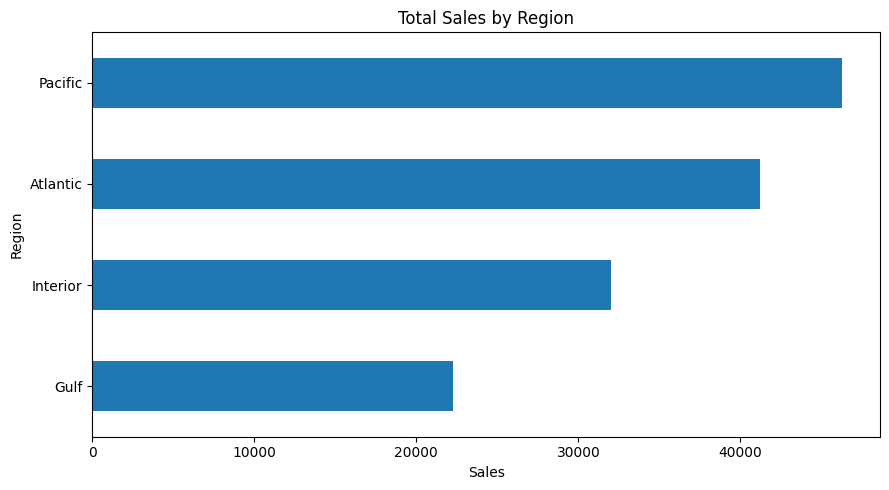

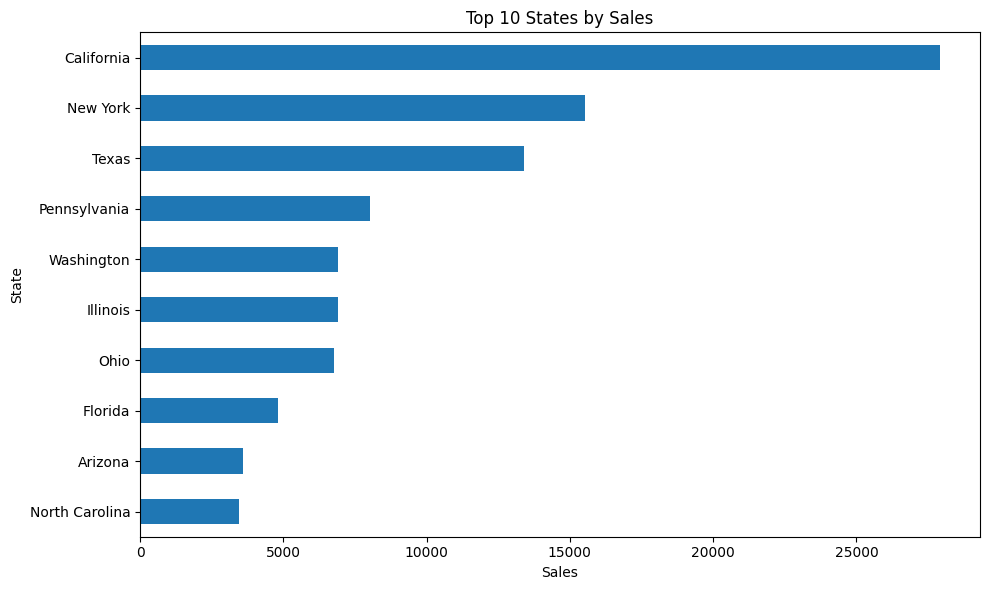

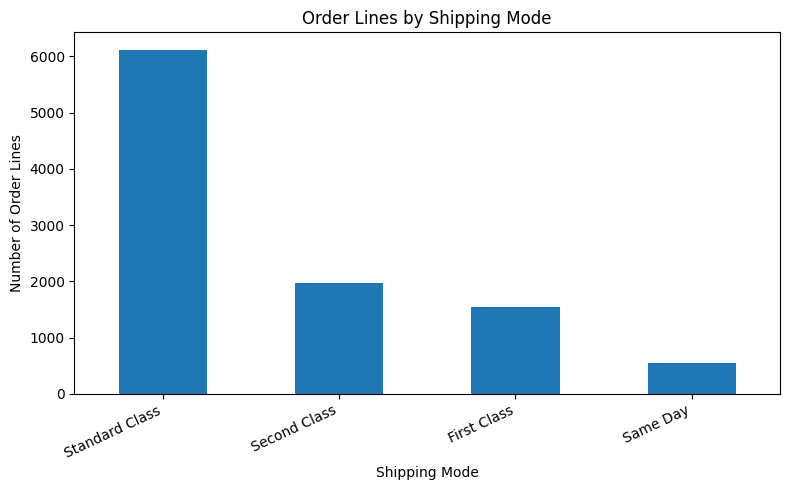

All three charts saved successfully in the outputs folder.


In [96]:


# Load the prepared dataset
df = pd.read_csv("outputs/geographic_analysis.csv")
os.makedirs("outputs", exist_ok=True)

# Convert sales to numeric
df["Sales"] = pd.to_numeric(df["Sales"], errors="coerce")

# Chart 1: Sales by region
region_sales = df.groupby("Region")["Sales"].sum().sort_values()

plt.figure(figsize=(9, 5))
region_sales.plot(kind="barh")
plt.title("Total Sales by Region")
plt.xlabel("Sales")
plt.ylabel("Region")
plt.tight_layout()
plt.savefig("outputs/sales_by_region.png", dpi=300)
plt.show()

# Chart 2: Top 10 states by sales
state_sales = (
    df.groupby("State/Province")["Sales"]
    .sum()
    .nlargest(10)
    .sort_values()
)

plt.figure(figsize=(10, 6))
state_sales.plot(kind="barh")
plt.title("Top 10 States by Sales")
plt.xlabel("Sales")
plt.ylabel("State")
plt.tight_layout()
plt.savefig("outputs/top_10_states_by_sales.png", dpi=300)
plt.show()

# Chart 3: Order-line count by shipping mode
shipping_counts = df["Ship Mode"].value_counts()

plt.figure(figsize=(8, 5))
shipping_counts.plot(kind="bar")
plt.title("Order Lines by Shipping Mode")
plt.xlabel("Shipping Mode")
plt.ylabel("Number of Order Lines")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.savefig("outputs/shipping_mode_distribution.png", dpi=300)
plt.show()

print("All three charts saved successfully in the outputs folder.")

In [97]:


df = pd.read_csv("outputs/geographic_analysis.csv")

for col in ["Sales", "Gross Profit", "Units"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

total_sales = df["Sales"].sum()
total_profit = df["Gross Profit"].sum()
total_units = df["Units"].sum()

top_region = df.groupby("Region")["Sales"].sum().idxmax()
top_state = df.groupby("State/Province")["Sales"].sum().idxmax()
top_product = df.groupby("Product Name")["Sales"].sum().idxmax()
top_ship_mode = df["Ship Mode"].value_counts().idxmax()

report = f"""
NASSAU CANDY DISTRIBUTOR — ANALYSIS SUMMARY
============================================

Total sales: ${total_sales:,.2f}
Total gross profit: ${total_profit:,.2f}
Total units sold: {total_units:,.0f}
Total records analyzed: {len(df):,}

Top region by sales: {top_region}
Top state by sales: {top_state}
Top product by sales: {top_product}
Most-used shipping mode: {top_ship_mode}

DATA QUALITY NOTE
Shipping dates appear unreliable.
Delivery-time and shipping-efficiency conclusions
should not be made from the recorded dates.
"""

print(report)

with open("outputs/project_summary.txt", "w", encoding="utf-8") as f:
    f.write(report)

print("Report saved to outputs/project_summary.txt")


NASSAU CANDY DISTRIBUTOR — ANALYSIS SUMMARY

Total sales: $141,783.63
Total gross profit: $93,442.80
Total units sold: 38,654
Total records analyzed: 10,194

Top region by sales: Pacific
Top state by sales: California
Top product by sales: Wonka Bar - Triple Dazzle Caramel
Most-used shipping mode: Standard Class

DATA QUALITY NOTE
Shipping dates appear unreliable.
Delivery-time and shipping-efficiency conclusions
should not be made from the recorded dates.

Report saved to outputs/project_summary.txt
